# Airfoil Self-Noise Prediction Using Machine Learning

### Machine Learning Capstone Project

**Course:** 23CSE301 Machine Learning  
**Track:** Regression  
**Dataset:** Airfoil Self-Noise  
**Dataset Source:** UCI Machine Learning Repository

## 1. Project Objective

The objective of this project is to build and compare multiple machine
learning regression models for predicting the scaled sound pressure
level of an airfoil using its aerodynamic and acoustic characteristics.

The project follows an end-to-end machine learning workflow consisting
of data loading, exploratory data analysis, data cleaning, feature
engineering, preprocessing, model training, hyperparameter tuning,
evaluation, and model comparison.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
print("Libraries imported successfully.")

Libraries imported successfully.


In [3]:
file_path = "../data/airfoil_self_noise.dat"

df = pd.read_csv(
    file_path,
    sep=r"\s+",
    header=None
)

df.head()

,0,1,2,3,4,5
0,800,0.0,0.3048,71.3,0.002663,126.201
1,1000,0.0,0.3048,71.3,0.002663,125.201
2,1250,0.0,0.3048,71.3,0.002663,125.951
3,1600,0.0,0.3048,71.3,0.002663,127.591
4,2000,0.0,0.3048,71.3,0.002663,127.461


In [4]:
df.columns = [
    "frequency",
    "angle_of_attack",
    "chord_length",
    "free_stream_velocity",
    "suction_side_displacement_thickness",
    "sound_pressure_level"
]

df.head()

,frequency,angle_of_attack,chord_length,free_stream_velocity,suction_side_displacement_thickness,sound_pressure_level
0,800,0.0,0.3048,71.3,0.002663,126.201
1,1000,0.0,0.3048,71.3,0.002663,125.201
2,1250,0.0,0.3048,71.3,0.002663,125.951
3,1600,0.0,0.3048,71.3,0.002663,127.591
4,2000,0.0,0.3048,71.3,0.002663,127.461


## 2. Dataset Loading and Initial Audit

In [5]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])
print("Dataset shape:", df.shape)

Number of rows: 1503
Number of columns: 6
Dataset shape: (1503, 6)


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1503 entries, 0 to 1502
Data columns (total 6 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   frequency                            1503 non-null   int64  
 1   angle_of_attack                      1503 non-null   float64
 2   chord_length                         1503 non-null   float64
 3   free_stream_velocity                 1503 non-null   float64
 4   suction_side_displacement_thickness  1503 non-null   float64
 5   sound_pressure_level                 1503 non-null   float64
dtypes: float64(5), int64(1)
memory usage: 70.6 KB


In [7]:
missing_values = df.isnull().sum()

print("Missing values in each column:")
print(missing_values)

Missing values in each column:
frequency                              0
angle_of_attack                        0
chord_length                           0
free_stream_velocity                   0
suction_side_displacement_thickness    0
sound_pressure_level                   0
dtype: int64


In [8]:
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


In [9]:
df.describe()

,frequency,angle_of_attack,chord_length,free_stream_velocity,suction_side_displacement_thickness,sound_pressure_level
count,1503.000000,1503.000000,1503.000000,1503.000000,1503.000000,1503.000000
mean,2886.380572,6.782302,0.136548,50.860745,0.011140,124.835943
std,3152.573137,5.918128,0.093541,15.572784,0.013150,6.898657
min,200.000000,0.000000,0.025400,31.700000,0.000401,103.380000
25%,800.000000,2.000000,0.050800,39.600000,0.002535,120.191000
50%,1600.000000,5.400000,0.101600,39.600000,0.004957,125.721000
75%,4000.000000,9.900000,0.228600,71.300000,0.015576,129.995500
max,20000.000000,22.200000,0.304800,71.300000,0.058411,140.987000


### Target Variable Distribution

The target variable is `sound_pressure_level`, which represents the
sound pressure level that the regression models will predict.

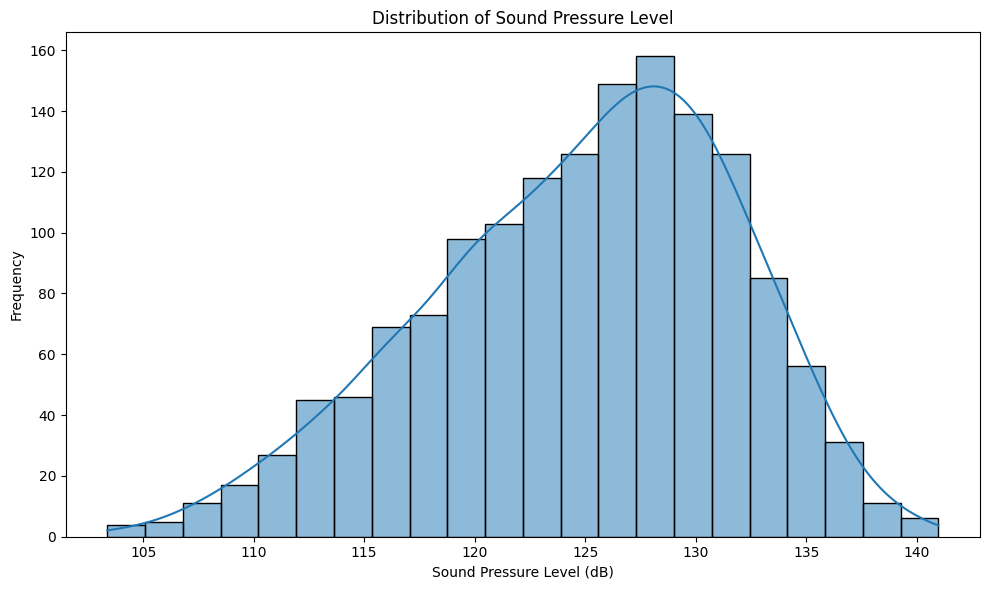

In [10]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="sound_pressure_level",
    kde=True
)

plt.title("Distribution of Sound Pressure Level")
plt.xlabel("Sound Pressure Level (dB)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

### Observation

The sound pressure level is distributed approximately around the
middle of the observed range, with the highest concentration of
observations occurring around 125–130 dB. The distribution appears
fairly smooth and broadly unimodal, with fewer observations at the
lower and higher extremes.

## 3. Exploratory Data Analysis

### 3.1 Distribution of Input Features

The distributions of the input features are examined to understand
their ranges, spread, concentration of observations, and potential
skewness.

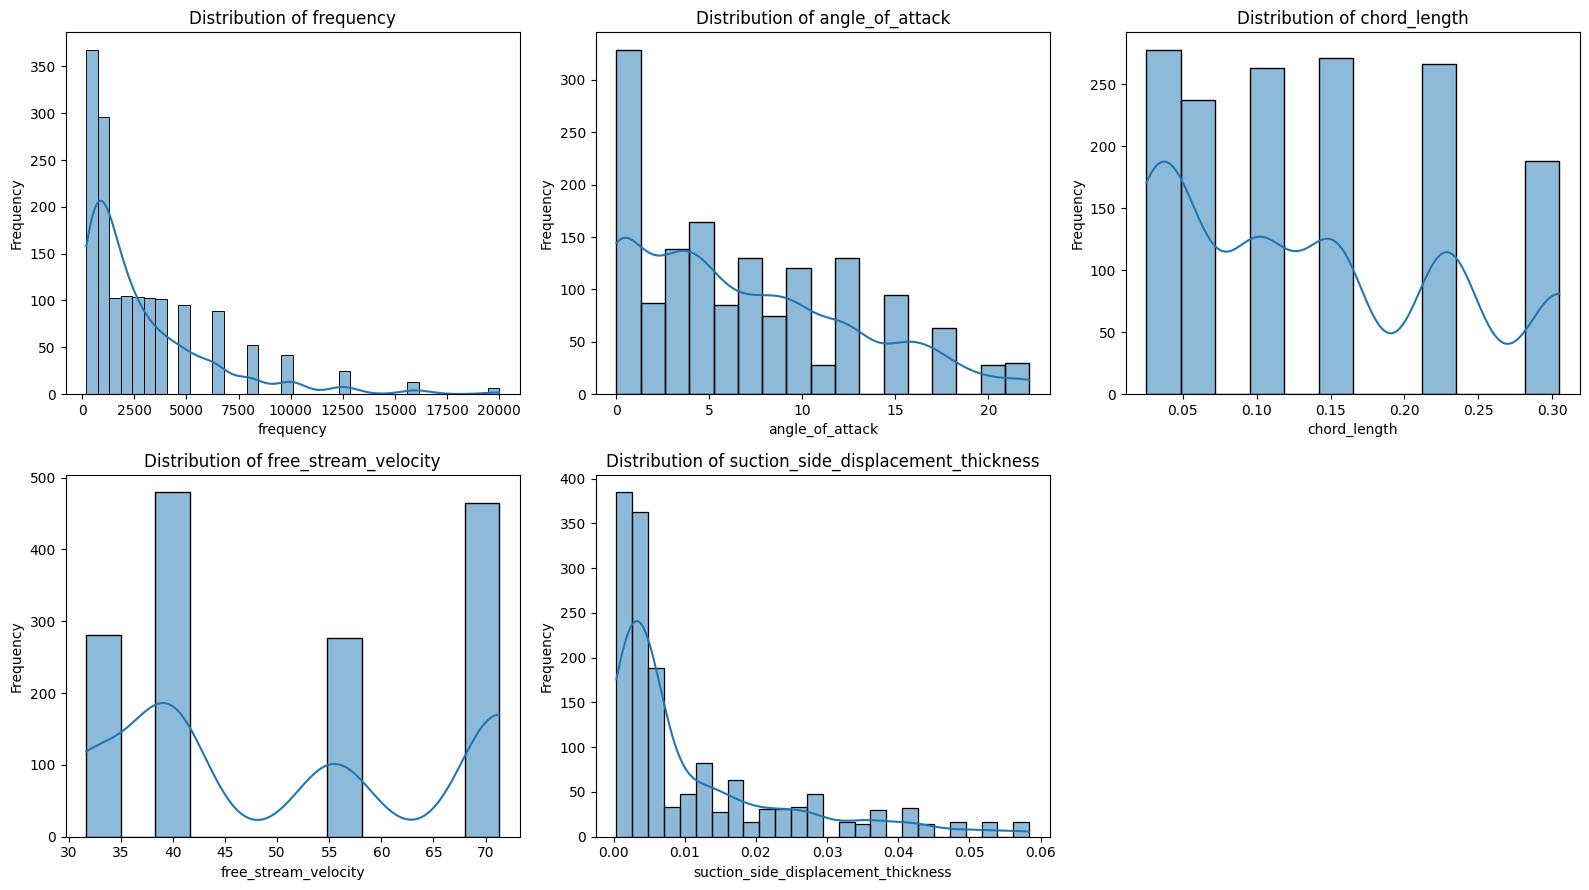

In [11]:
feature_columns = [
    "frequency",
    "angle_of_attack",
    "chord_length",
    "free_stream_velocity",
    "suction_side_displacement_thickness"
]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))

axes = axes.flatten()

for i, column in enumerate(feature_columns):
    sns.histplot(
        data=df,
        x=column,
        kde=True,
        ax=axes[i]
    )

    axes[i].set_title(f"Distribution of {column}")
    axes[i].set_xlabel(column)
    axes[i].set_ylabel("Frequency")

# Hide unused subplot
axes[-1].set_visible(False)

plt.tight_layout()
plt.show()

### Observations

- **Frequency:** The distribution is highly right-skewed. Most observations are concentrated at lower frequency values, while relatively fewer observations occur at higher frequencies.

- **Angle of Attack:** The observations are concentrated at lower angles of attack, with values extending to higher angles. The distribution is not uniform and contains several distinct concentration regions.

- **Chord Length:** The feature contains a limited number of distinct values, with some chord lengths occurring more frequently than others. This indicates that the experiments were conducted using specific airfoil chord lengths rather than a continuously varying range.

- **Free-stream Velocity:** The observations are concentrated around a few distinct velocity values. This indicates that the experiments used specific experimental velocity settings.

- **Suction-side Displacement Thickness:** The distribution is strongly right-skewed, with most observations having relatively small displacement-thickness values and fewer observations at larger values.

### 3.2 Correlation Analysis

Correlation analysis is used to examine the strength and direction
of the linear relationships between the input features and the target
variable.

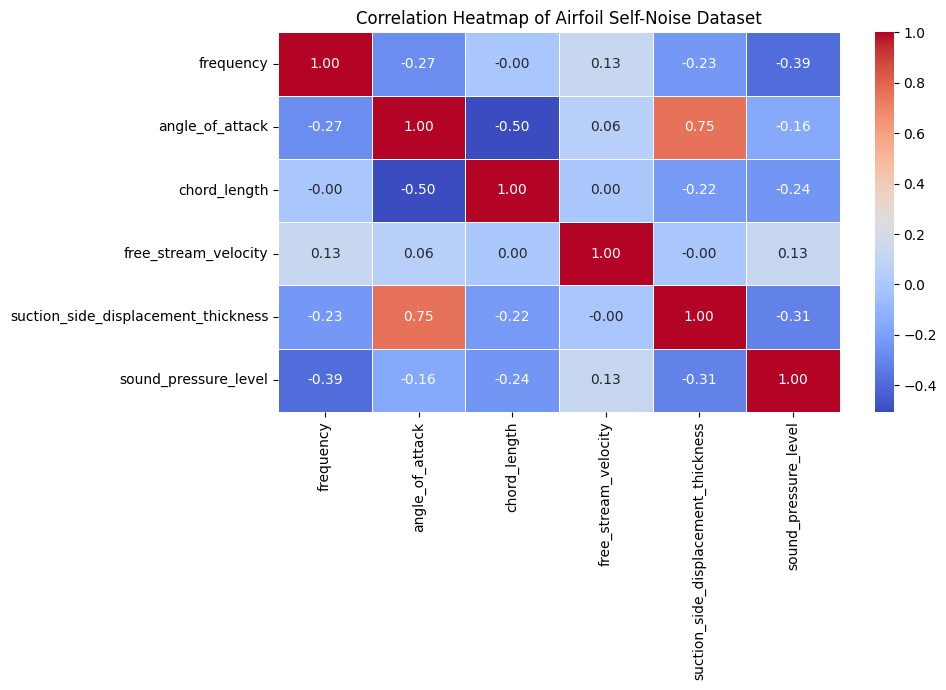

In [12]:
correlation_matrix = df.corr(numeric_only=True)

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Airfoil Self-Noise Dataset")

plt.tight_layout()
plt.show()

### Observations

- Frequency has the strongest linear correlation with the target among the five input features, with a correlation coefficient of approximately -0.39. This indicates a moderate negative linear relationship with sound pressure level.

- Suction-side displacement thickness also shows a negative relationship with the target, with a correlation coefficient of approximately -0.31.

- Chord length has a weaker negative correlation with sound pressure level, approximately -0.24.

- Angle of attack has a relatively weak negative correlation with the target, approximately -0.16.

- Free-stream velocity has a weak positive correlation with sound pressure level, approximately +0.13.

- Angle of attack and suction-side displacement thickness have a relatively strong positive correlation of approximately +0.75, indicating that these two input variables have a substantial linear relationship in this dataset.

- Correlation measures linear association only. Therefore, a weak correlation does not necessarily mean that a feature has no predictive value for a machine learning model.

### 3.3 Feature-Target Relationships

Scatter plots are used to visually examine how each input feature
relates to the sound pressure level.

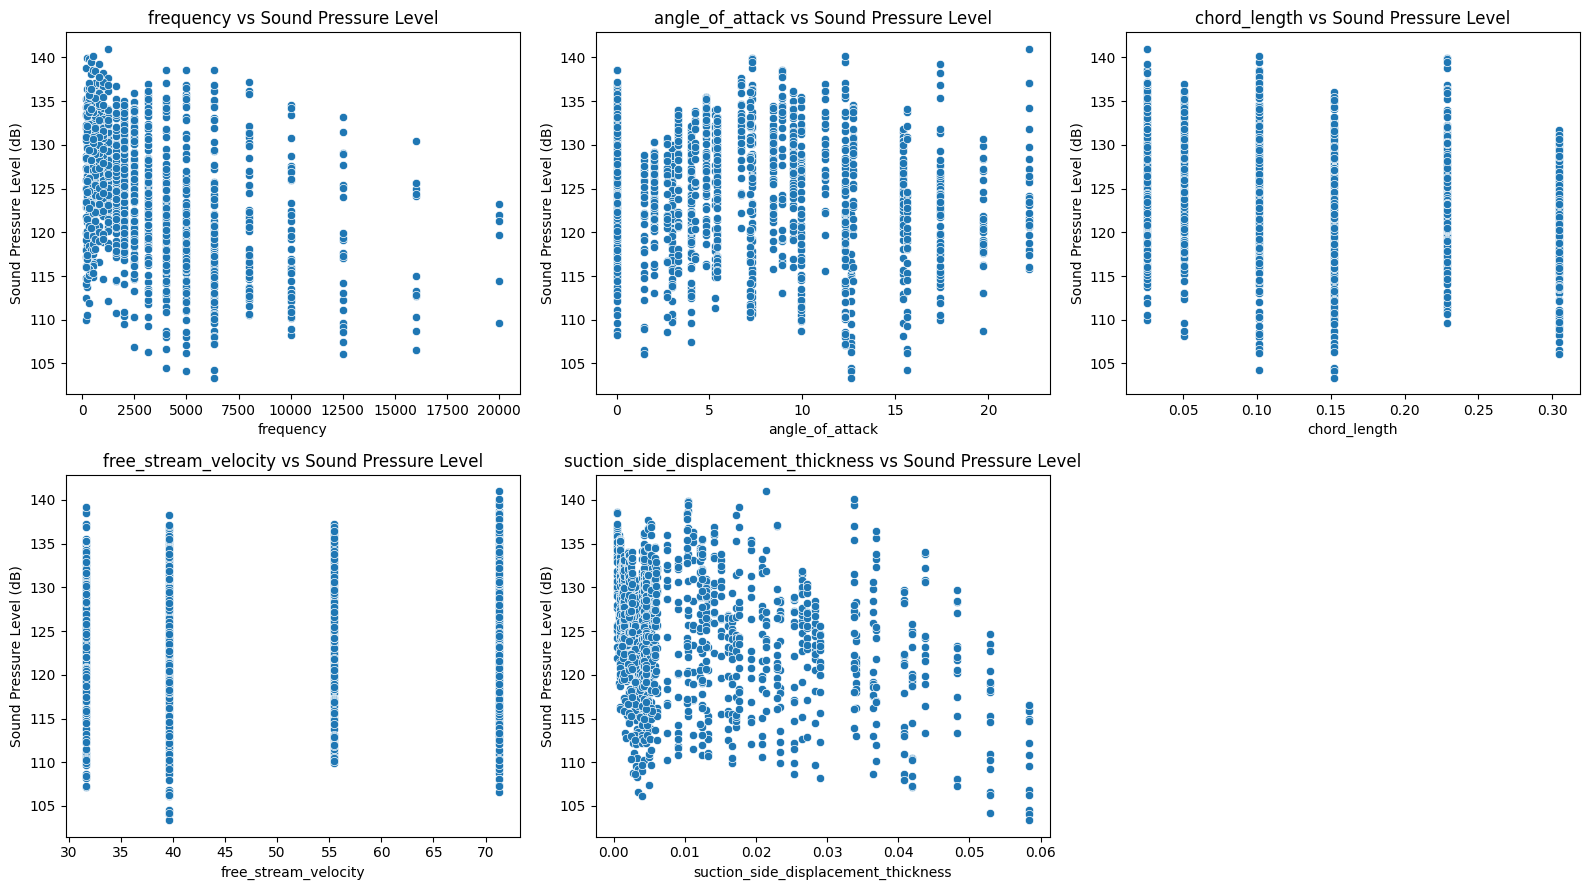

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

axes = axes.flatten()

for i, column in enumerate(feature_columns):
    sns.scatterplot(
        data=df,
        x=column,
        y="sound_pressure_level",
        ax=axes[i]
    )

    axes[i].set_title(
        f"{column} vs Sound Pressure Level"
    )
    axes[i].set_xlabel(column)
    axes[i].set_ylabel("Sound Pressure Level (dB)")

axes[-1].set_visible(False)

plt.tight_layout()
plt.show()

### Observations

- **Frequency vs Sound Pressure Level:** The plot shows a generally negative relationship. Higher sound pressure levels are more concentrated at lower frequency values, while the spread of sound pressure levels tends to decrease at higher frequencies. This agrees with the negative correlation observed in the correlation heatmap.

- **Angle of Attack vs Sound Pressure Level:** The relationship appears relatively scattered, with no clear simple linear trend. Sound pressure levels vary considerably at different angles of attack. Therefore, angle of attack may have a more complex relationship with the target than can be explained by a simple linear association.

- **Chord Length vs Sound Pressure Level:** The plot shows noticeable differences in the distribution of sound pressure levels across the discrete chord-length values. Some chord lengths exhibit wider ranges of sound pressure levels than others, suggesting that chord length may contribute to the prediction of the target.

- **Free-stream Velocity vs Sound Pressure Level:** The observations form distinct vertical groups because the dataset contains several specific velocity values. The target varies considerably within each velocity group, indicating that velocity alone does not explain the variation in sound pressure level.

- **Suction-side Displacement Thickness vs Sound Pressure Level:** The plot shows a generally negative relationship, although there is substantial variation in the target. Higher displacement-thickness values tend to be associated with lower sound pressure levels, consistent with the negative correlation observed in the heatmap.

### 4.1 Missing Value Analysis


In [14]:
missing_values = df.isnull().sum()

print("Missing values in each column:")
print(missing_values)

print("\nTotal missing values:", missing_values.sum())

Missing values in each column:
frequency                              0
angle_of_attack                        0
chord_length                           0
free_stream_velocity                   0
suction_side_displacement_thickness    0
sound_pressure_level                   0
dtype: int64

Total missing values: 0


### Observation

No missing values were found in any column of the dataset. Therefore,
no missing-value imputation or row deletion was required.

### 4.2 Duplicate Record Check

In [15]:
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


### Observation

No duplicate records were identified in the dataset. Therefore, no
duplicate rows were removed.

### 4.3 Outlier Detection

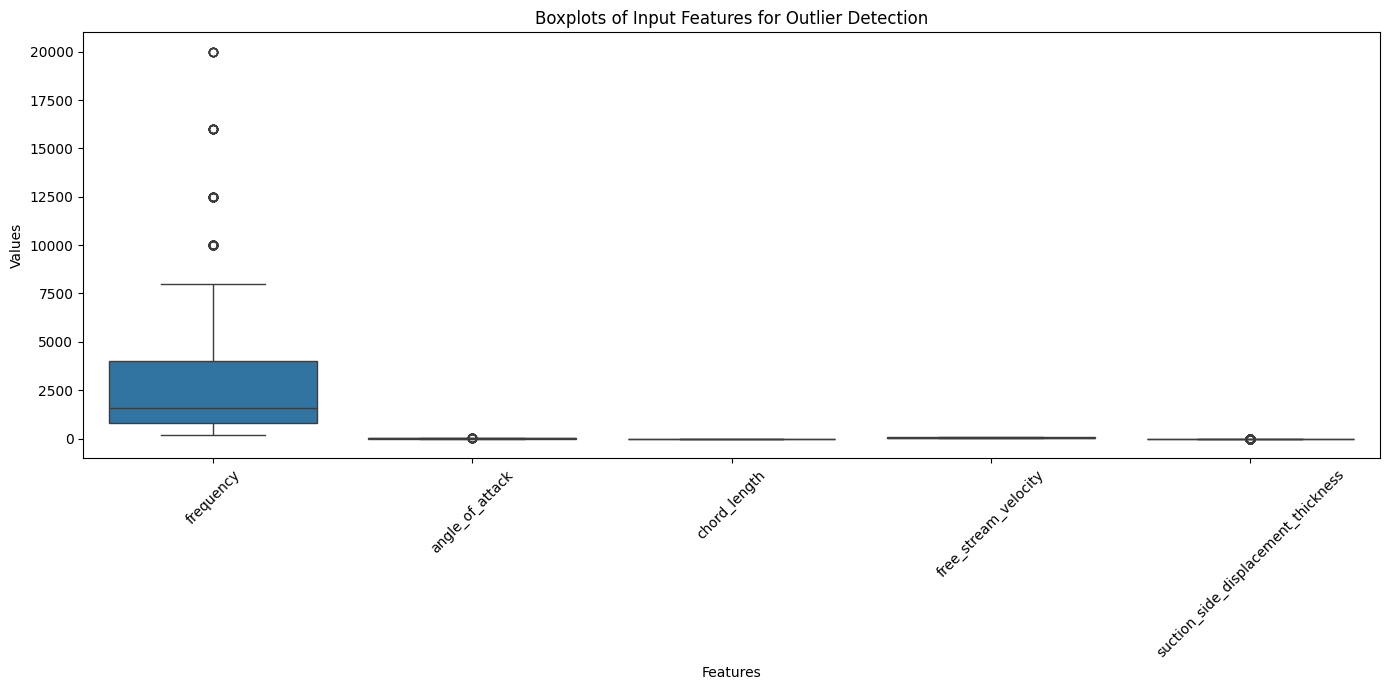

In [16]:
plt.figure(figsize=(14, 7))

sns.boxplot(data=df[feature_columns])

plt.title("Boxplots of Input Features for Outlier Detection")
plt.xlabel("Features")
plt.ylabel("Values")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

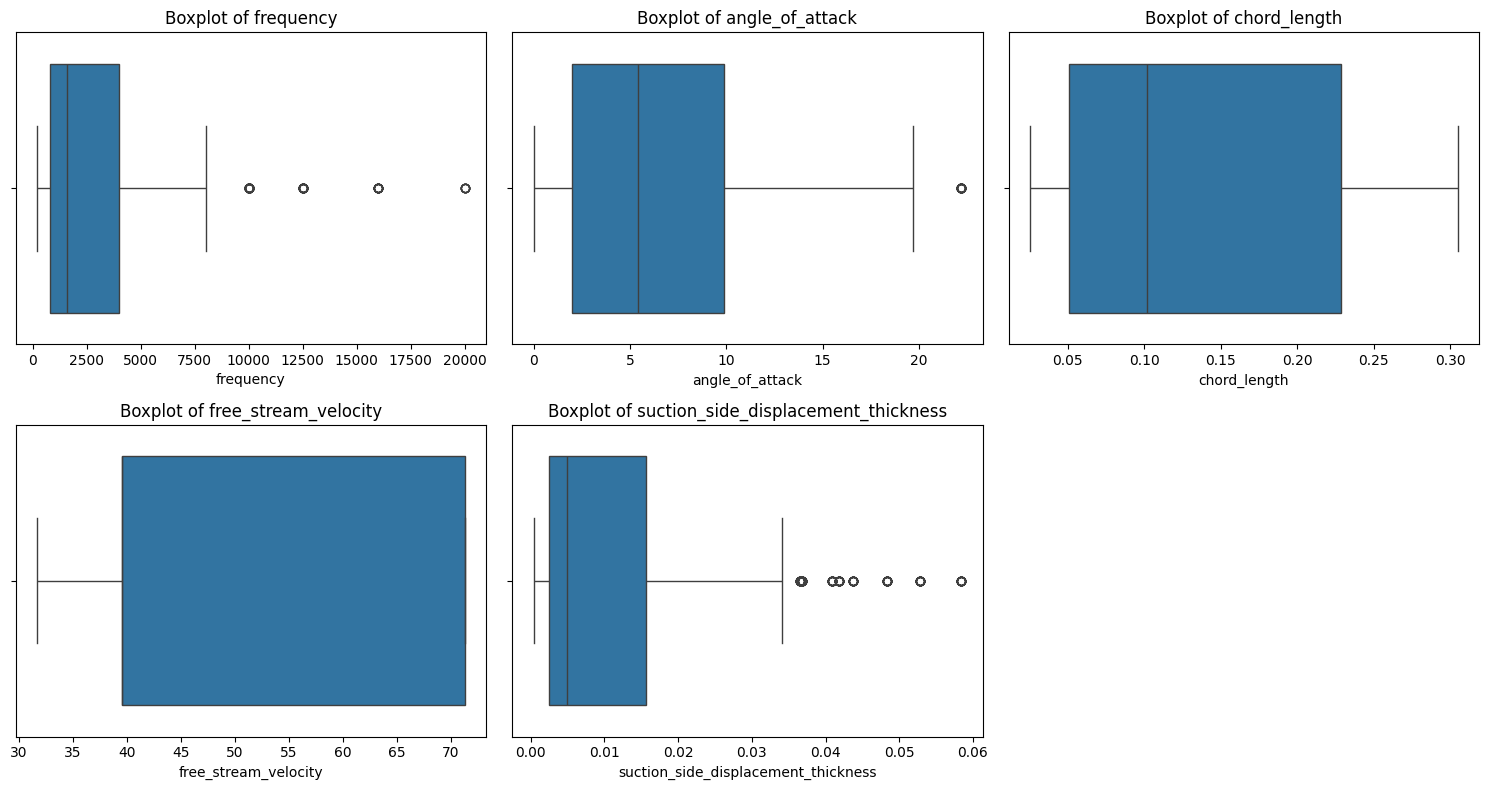

In [17]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

axes = axes.flatten()

for i, column in enumerate(feature_columns):
    sns.boxplot(
        x=df[column],
        ax=axes[i]
    )

    axes[i].set_title(f"Boxplot of {column}")
    axes[i].set_xlabel(column)

axes[-1].set_visible(False)

plt.tight_layout()
plt.show()

### 4.4 IQR Analysis

In [18]:
outlier_summary = []

for column in feature_columns:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outlier_count = (
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ).sum()

    outlier_summary.append({
        "Feature": column,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": outlier_count
    })

outlier_summary = pd.DataFrame(outlier_summary)

outlier_summary

,Feature,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count
0,frequency,800.000000,4000.000000,3200.000000,-4000.000000,8800.000000,86
1,angle_of_attack,2.000000,9.900000,7.900000,-9.850000,21.750000,30
2,chord_length,0.050800,0.228600,0.177800,-0.215900,0.495300,0
3,free_stream_velocity,39.600000,71.300000,31.700000,-7.950000,118.850000,0
4,suction_side_displacement_thickness,0.002535,0.015576,0.013041,-0.017026,0.035137,124


### Observation

The IQR analysis identifies potential outliers in frequency, angle of
attack, and suction-side displacement thickness, while chord length
and free-stream velocity have no observations outside their IQR bounds.

The frequency feature has 86 potential outliers, angle of attack has
30, and suction-side displacement thickness has 124. However, these
observations are not automatically treated as erroneous because the
dataset contains experimental measurements covering a range of
operating conditions.

Therefore, the statistically identified potential outliers are
retained rather than removed. This avoids losing potentially valid
experimental information. The models will subsequently be evaluated
using the complete available observations.

### 5. Feature Engineering
### 5.1 Log Transformation of Frequency

The frequency feature is strongly right-skewed, with values ranging from
200 Hz to 20,000 Hz. A logarithmic transformation is applied to reduce
the effect of the long right tail and compress large frequency values.

The engineered feature is calculated as:

log_frequency = log(1 + frequency)

In [19]:
# Create a copy for feature engineering
df_engineered = df.copy()

# Apply logarithmic transformation to frequency
df_engineered["log_frequency"] = np.log1p(
    df_engineered["frequency"]
)

# Display the original and engineered feature
df_engineered[
    ["frequency", "log_frequency"]
].head(10)

,frequency,log_frequency
0,800,6.685861
1,1000,6.908755
2,1250,7.131699
3,1600,7.378384
4,2000,7.601402
5,2500,7.824446
6,3150,8.055475
7,4000,8.294300
8,5000,8.517393
9,6300,8.748464


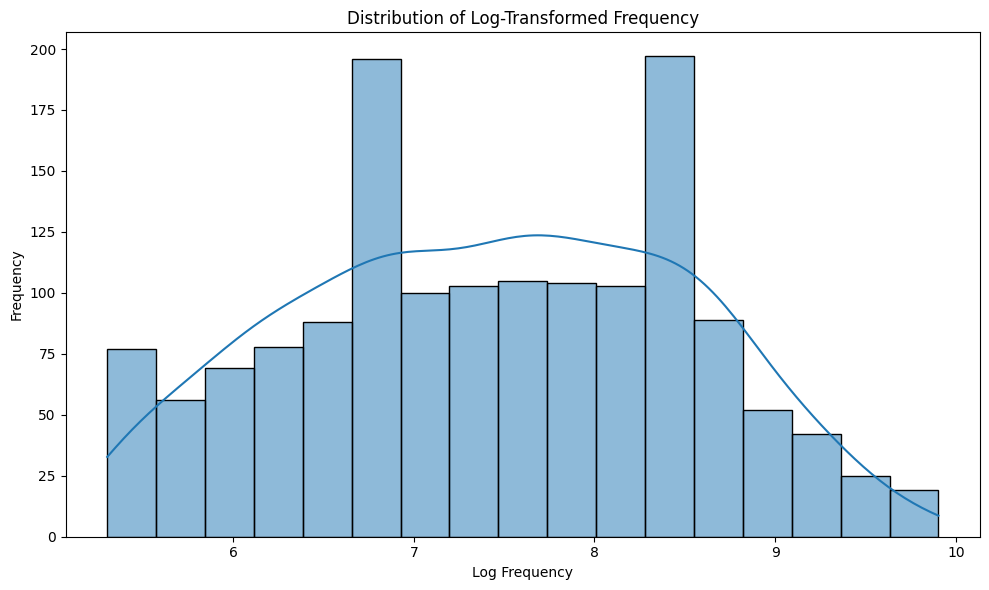

In [20]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df_engineered,
    x="log_frequency",
    kde=True
)

plt.title("Distribution of Log-Transformed Frequency")
plt.xlabel("Log Frequency")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

### Observation

The log transformation compresses the higher frequency values and
reduces the strong right-skewness observed in the original frequency
distribution. The transformed frequency has a more balanced spread
across its range while retaining the ordering of the original
observations.

## 6. Feature and Target Selection

The five original variables are used as input features, along with the
engineered `log_frequency` feature. The target variable is
`sound_pressure_level`.

In [21]:
# Define the final feature columns
final_features = [
    "frequency",
    "log_frequency",
    "angle_of_attack",
    "chord_length",
    "free_stream_velocity",
    "suction_side_displacement_thickness"
]

X = df_engineered[final_features]
y = df_engineered["sound_pressure_level"]

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

Feature matrix shape: (1503, 6)
Target shape: (1503,)


In [22]:
X.head()

,frequency,log_frequency,angle_of_attack,chord_length,free_stream_velocity,suction_side_displacement_thickness
0,800,6.685861,0.0,0.3048,71.3,0.002663
1,1000,6.908755,0.0,0.3048,71.3,0.002663
2,1250,7.131699,0.0,0.3048,71.3,0.002663
3,1600,7.378384,0.0,0.3048,71.3,0.002663
4,2000,7.601402,0.0,0.3048,71.3,0.002663


## 7. Train-Test Split

The dataset is divided into training and testing sets using an 80:20
split. The training set is used to train the regression models, while
the test set is kept separate for final performance evaluation.

A fixed random state is used to ensure that the split is reproducible.

In [23]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)
print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

Training feature shape: (1202, 6)
Testing feature shape: (301, 6)
Training target shape: (1202,)
Testing target shape: (301,)


### 8.1 Standardization


In [24]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [25]:
print("Training means after scaling:")
print(X_train_scaled.mean(axis=0))

print("\nTraining standard deviations after scaling:")
print(X_train_scaled.std(axis=0))

Training means after scaling:
[ 5.91133724e-18 -7.83252184e-17  3.54680234e-17  2.86699856e-16
  3.04988056e-16  4.43350293e-18]

Training standard deviations after scaling:
[1. 1. 1. 1. 1. 1.]


In [26]:
from sklearn.linear_model import (
    LinearRegression,
    Ridge,
    Lasso,
    ElasticNet
)

from sklearn.preprocessing import PolynomialFeatures

from sklearn.pipeline import Pipeline

from sklearn.neighbors import KNeighborsRegressor

from sklearn.svm import SVR

from sklearn.tree import DecisionTreeRegressor

from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor
)

### Linear Regression

Linear Regression models the relationship between the input features
and the continuous target variable by fitting a linear equation.

The model assumes that the target can be represented approximately as
a weighted combination of the input features.

In [27]:
linear_model = LinearRegression()

linear_model.fit(
    X_train_scaled,
    y_train
)
y_train_pred_linear = linear_model.predict(
    X_train_scaled
)

y_test_pred_linear = linear_model.predict(
    X_test_scaled
)



In [28]:
from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error
)

import numpy as np
train_r2_linear = r2_score(
    y_train,
    y_train_pred_linear
)

test_r2_linear = r2_score(
    y_test,
    y_test_pred_linear
)

train_rmse_linear = np.sqrt(
    mean_squared_error(
        y_train,
        y_train_pred_linear
    )
)

test_rmse_linear = np.sqrt(
    mean_squared_error(
        y_test,
        y_test_pred_linear
    )
)

train_mae_linear = mean_absolute_error(
    y_train,
    y_train_pred_linear
)

test_mae_linear = mean_absolute_error(
    y_test,
    y_test_pred_linear
)

print("Linear Regression")
print("----------------------------")
print("Train R²  :", train_r2_linear)
print("Test R²   :", test_r2_linear)
print("Train RMSE:", train_rmse_linear)
print("Test RMSE :", test_rmse_linear)
print("Train MAE :", train_mae_linear)
print("Test MAE  :", test_mae_linear)

Linear Regression
----------------------------
Train R²  : 0.5163663025194639
Test R²   : 0.5662803796473026
Train RMSE: 4.76340087389985
Test RMSE : 4.661409252694093
Train MAE : 3.676237796109962
Test MAE  : 3.6361832152782885


In [29]:
linear_coefficients = pd.DataFrame({
    "Feature": final_features,
    "Coefficient": linear_model.coef_
})

linear_coefficients

,Feature,Coefficient
0,frequency,-2.813029
1,log_frequency,-1.506696
2,angle_of_attack,-2.447656
3,chord_length,-3.242435
4,free_stream_velocity,1.541112
5,suction_side_displacement_thickness,-1.874812


In [30]:
print("Intercept:", linear_model.intercept_)

Intercept: 124.87696006655574


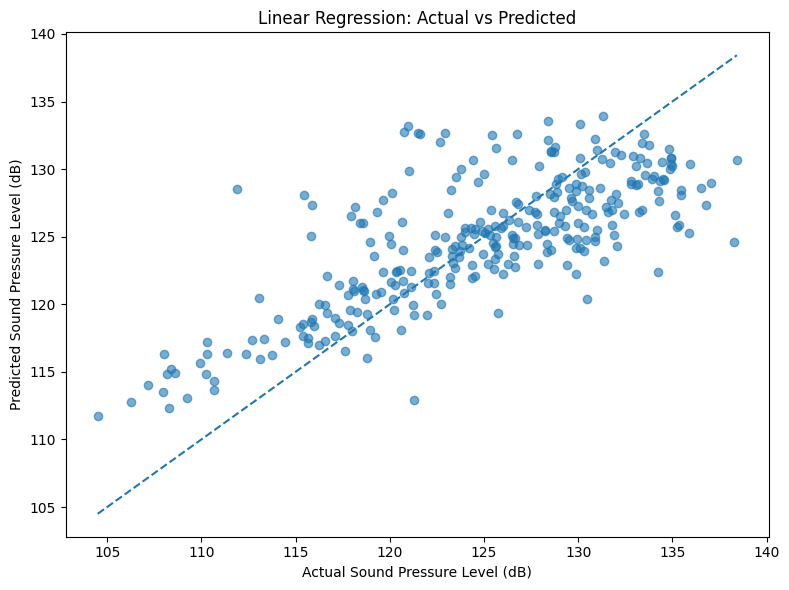

In [31]:
### Actual vs Predicted Values
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_test_pred_linear,
    alpha=0.6
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.xlabel("Actual Sound Pressure Level (dB)")
plt.ylabel("Predicted Sound Pressure Level (dB)")
plt.title("Linear Regression: Actual vs Predicted")

plt.tight_layout()
plt.show()

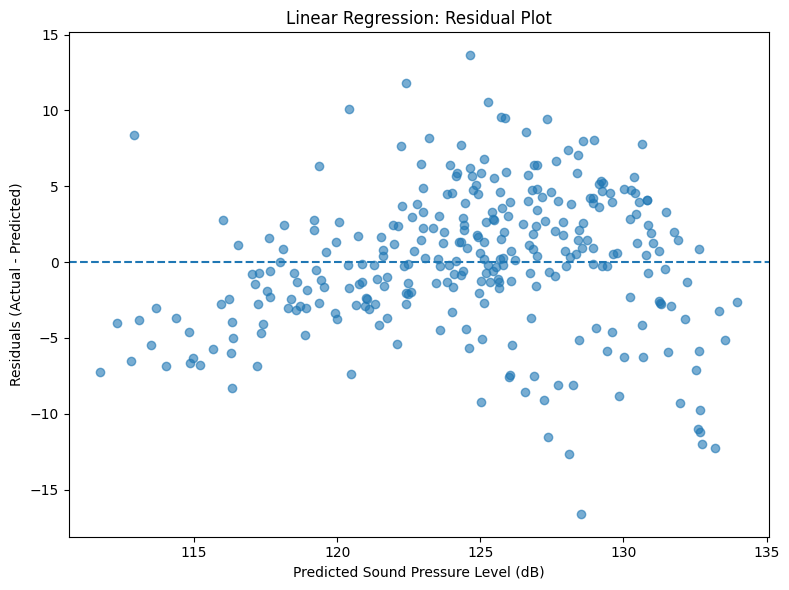

In [32]:
residuals_linear = y_test - y_test_pred_linear

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test_pred_linear,
    residuals_linear,
    alpha=0.6
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.xlabel("Predicted Sound Pressure Level (dB)")
plt.ylabel("Residuals (Actual - Predicted)")
plt.title("Linear Regression: Residual Plot")

plt.tight_layout()
plt.show()

### Observation

The actual versus predicted plot shows that the predictions generally
follow the diagonal reference line, indicating that the Linear
Regression model captures a substantial part of the relationship
between the input features and sound pressure level.

However, considerable scatter around the reference line is visible,
with some observations showing larger prediction errors. This indicates
that a simple linear model does not completely capture the variation
in sound pressure level.

### Residual Analysis

The residuals are distributed on both sides of the zero reference line,
indicating that the model produces both underpredictions and
overpredictions.

However, the residuals do not form a perfectly random and uniformly
spread pattern around zero. Some structure and relatively large
residuals are visible across the prediction range. This suggests that
the linear model may not capture all the underlying relationships in
the dataset.

### Ridge Regression

In [33]:
ridge_model = Ridge(alpha=1.0)

ridge_model.fit(
    X_train_scaled,
    y_train
)

y_train_pred_ridge = ridge_model.predict(
    X_train_scaled
)

y_test_pred_ridge = ridge_model.predict(
    X_test_scaled
)

In [34]:
train_r2_ridge = r2_score(
    y_train,
    y_train_pred_ridge
)

test_r2_ridge = r2_score(
    y_test,
    y_test_pred_ridge
)

train_rmse_ridge = np.sqrt(
    mean_squared_error(
        y_train,
        y_train_pred_ridge
    )
)

test_rmse_ridge = np.sqrt(
    mean_squared_error(
        y_test,
        y_test_pred_ridge
    )
)

train_mae_ridge = mean_absolute_error(
    y_train,
    y_train_pred_ridge
)

test_mae_ridge = mean_absolute_error(
    y_test,
    y_test_pred_ridge
)

print("Ridge Regression")
print("----------------------------")
print("Train R²  :", train_r2_ridge)
print("Test R²   :", test_r2_ridge)
print("Train RMSE:", train_rmse_ridge)
print("Test RMSE :", test_rmse_ridge)
print("Train MAE :", train_mae_ridge)
print("Test MAE  :", test_mae_ridge)

Ridge Regression
----------------------------
Train R²  : 0.5163653555043084
Test R²   : 0.5661233406707507
Train RMSE: 4.76340553756435
Test RMSE : 4.662253065902211
Train MAE : 3.6767860033660176
Test MAE  : 3.637411647820252


In [35]:
ridge_coefficients = pd.DataFrame({
    "Feature": final_features,
    "Coefficient": ridge_model.coef_
})

ridge_coefficients

,Feature,Coefficient
0,frequency,-2.807254
1,log_frequency,-1.508398
2,angle_of_attack,-2.439381
3,chord_length,-3.236096
4,free_stream_velocity,1.538797
5,suction_side_displacement_thickness,-1.877209


### Ridge Regression Results

With alpha = 1.0, Ridge Regression produced performance very similar
to Linear Regression. The test R² was 0.5661, compared with 0.5663
for Linear Regression, while the test RMSE and MAE were slightly
higher.

The Ridge coefficients were slightly smaller in magnitude than the
corresponding Linear Regression coefficients, demonstrating the
coefficient-shrinkage effect of L2 regularization.

For this regularization strength, Ridge Regression did not provide a
meaningful improvement over the Linear Regression model on the test
set.

### 10.3 Lasso Regression

Lasso Regression is a linear regression model with L1 regularization.
The L1 penalty encourages coefficient shrinkage and can reduce some
coefficients exactly to zero, making Lasso useful for feature
selection.

The Lasso objective function is:

MSE + λ × Σ|β|

where λ controls the strength of regularization.

In [36]:
lasso_model = Lasso(alpha=0.1)

lasso_model.fit(
    X_train_scaled,
    y_train
)
y_train_pred_lasso = lasso_model.predict(
    X_train_scaled
)

y_test_pred_lasso = lasso_model.predict(
    X_test_scaled
)

In [37]:
train_r2_lasso = r2_score(
    y_train,
    y_train_pred_lasso
)

test_r2_lasso = r2_score(
    y_test,
    y_test_pred_lasso
)

train_rmse_lasso = np.sqrt(
    mean_squared_error(
        y_train,
        y_train_pred_lasso
    )
)

test_rmse_lasso = np.sqrt(
    mean_squared_error(
        y_test,
        y_test_pred_lasso
    )
)

train_mae_lasso = mean_absolute_error(
    y_train,
    y_train_pred_lasso
)

test_mae_lasso = mean_absolute_error(
    y_test,
    y_test_pred_lasso
)

print("Lasso Regression")
print("----------------------------")
print("Train R²  :", train_r2_lasso)
print("Test R²   :", test_r2_lasso)
print("Train RMSE:", train_rmse_lasso)
print("Test RMSE :", test_rmse_lasso)
print("Train MAE :", train_mae_lasso)
print("Test MAE  :", test_mae_lasso)

Lasso Regression
----------------------------
Train R²  : 0.5144393916800065
Test R²   : 0.5576810094892071
Train RMSE: 4.772880697696318
Test RMSE : 4.707393380368223
Train MAE : 3.712434940702757
Test MAE  : 3.6958008740889037


In [38]:
lasso_coefficients = pd.DataFrame({
    "Feature": final_features,
    "Coefficient": lasso_model.coef_
})

lasso_coefficients

,Feature,Coefficient
0,frequency,-2.706900
1,log_frequency,-1.397456
2,angle_of_attack,-2.121458
3,chord_length,-2.989195
4,free_stream_velocity,1.395645
5,suction_side_displacement_thickness,-1.910711


### Lasso Regression Results

With alpha = 0.1, Lasso Regression achieved a test R² of 0.5577,
with a test RMSE of 4.7074 dB and a test MAE of 3.6958 dB.

Compared with Linear Regression and Ridge Regression at the tested
regularization strengths, Lasso produced a lower test R² and higher
prediction errors.

The L1 penalty reduced the magnitude of the model coefficients.
However, none of the coefficients became exactly zero, so no feature
was completely eliminated at this regularization strength.

### 10.4 ElasticNet Regression

ElasticNet combines L1 and L2 regularization. It combines the
coefficient-shrinkage behavior of Ridge Regression with the potential
feature-selection behavior of Lasso Regression.

The model is controlled by two important hyperparameters:
`alpha`, which controls the overall regularization strength, and
`l1_ratio`, which controls the balance between L1 and L2 penalties.

In [39]:
from sklearn.linear_model import ElasticNet

elastic_model = ElasticNet(
    alpha=0.1,
    l1_ratio=0.5,
    random_state=42
)

elastic_model.fit(
    X_train_scaled,
    y_train
)
y_train_pred_elastic = elastic_model.predict(
    X_train_scaled
)

y_test_pred_elastic = elastic_model.predict(
    X_test_scaled
)

In [40]:
train_r2_elastic = r2_score(
    y_train,
    y_train_pred_elastic
)

test_r2_elastic = r2_score(
    y_test,
    y_test_pred_elastic
)

train_rmse_elastic = np.sqrt(
    mean_squared_error(
        y_train,
        y_train_pred_elastic
    )
)

test_rmse_elastic = np.sqrt(
    mean_squared_error(
        y_test,
        y_test_pred_elastic
    )
)

train_mae_elastic = mean_absolute_error(
    y_train,
    y_train_pred_elastic
)

test_mae_elastic = mean_absolute_error(
    y_test,
    y_test_pred_elastic
)

print("ElasticNet Regression")
print("----------------------------")
print("Train R²  :", train_r2_elastic)
print("Test R²   :", test_r2_elastic)
print("Train RMSE:", train_rmse_elastic)
print("Test RMSE :", test_rmse_elastic)
print("Train MAE :", train_mae_elastic)
print("Test MAE  :", test_mae_elastic)

ElasticNet Regression
----------------------------
Train R²  : 0.5115205058521453
Test R²   : 0.5503531198326228
Train RMSE: 4.78720498536676
Test RMSE : 4.746226847603658
Train MAE : 3.7375332940409107
Test MAE  : 3.7405101750683083


In [41]:
elastic_coefficients = pd.DataFrame({
    "Feature": final_features,
    "Coefficient": elastic_model.coef_
})

elastic_coefficients

,Feature,Coefficient
0,frequency,-2.486240
1,log_frequency,-1.510386
2,angle_of_attack,-1.921260
3,chord_length,-2.805841
4,free_stream_velocity,1.350395
5,suction_side_displacement_thickness,-1.952571


### ElasticNet Regression Results

With alpha = 0.1 and l1_ratio = 0.5, ElasticNet Regression achieved a
test R² of 0.5504, with a test RMSE of 4.7462 dB and a test MAE of
3.7405 dB.

At the selected regularization settings, ElasticNet produced a lower
test R² and higher prediction errors than Linear Regression, Ridge
Regression, and Lasso Regression.

The coefficients were reduced in magnitude due to the combined L1 and
L2 regularization. However, none of the coefficients became exactly
zero, so no feature was eliminated at this regularization strength.

### 10.5 Polynomial Regression

Polynomial Regression extends Linear Regression by transforming the
input features into polynomial terms. This allows the model to capture
nonlinear relationships between the predictors and the target.

A degree-2 polynomial model can include squared terms and interaction
terms between features.

Polynomial Regression is evaluated to determine whether nonlinear
relationships improve prediction compared with the linear models.

In [42]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline

polynomial_model = Pipeline([
    ("polynomial_features", PolynomialFeatures(
        degree=2,
        include_bias=False
    )),
    ("linear_regression", LinearRegression())
])

polynomial_model.fit(
    X_train_scaled,
    y_train
)
y_train_pred_poly = polynomial_model.predict(
    X_train_scaled
)

y_test_pred_poly = polynomial_model.predict(
    X_test_scaled
)

In [43]:
train_r2_poly = r2_score(
    y_train,
    y_train_pred_poly
)

test_r2_poly = r2_score(
    y_test,
    y_test_pred_poly
)

train_rmse_poly = np.sqrt(
    mean_squared_error(
        y_train,
        y_train_pred_poly
    )
)

test_rmse_poly = np.sqrt(
    mean_squared_error(
        y_test,
        y_test_pred_poly
    )
)

train_mae_poly = mean_absolute_error(
    y_train,
    y_train_pred_poly
)

test_mae_poly = mean_absolute_error(
    y_test,
    y_test_pred_poly
)

print("Polynomial Regression")
print("----------------------------")
print("Train R²  :", train_r2_poly)
print("Test R²   :", test_r2_poly)
print("Train RMSE:", train_rmse_poly)
print("Test RMSE :", test_rmse_poly)
print("Train MAE :", train_mae_poly)
print("Test MAE  :", test_mae_poly)

Polynomial Regression
----------------------------
Train R²  : 0.7390467059199803
Test R²   : 0.7256346041735839
Train RMSE: 3.49897022842315
Test RMSE : 3.7074676232501105
Train MAE : 2.6799063827950813
Test MAE  : 2.838206312762725


### Polynomial Regression Results

The degree-2 Polynomial Regression model achieved a test R² of 0.7256,
with a test RMSE of 3.7075 dB and a test MAE of 2.8382 dB.

Compared with the linear and regularized regression models tested
previously, Polynomial Regression achieved higher test R² and lower
test RMSE and MAE.

The training and testing R² values are relatively close, suggesting
that the model does not show a large train-test performance gap.
The improvement indicates that nonlinear relationships and
interactions between the input features may be useful for predicting
sound pressure level.

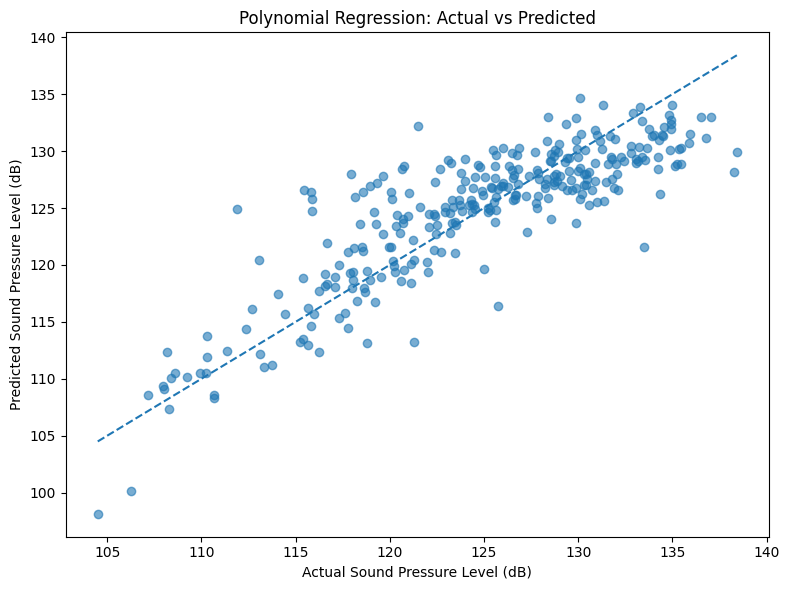

In [44]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_test_pred_poly,
    alpha=0.6
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.xlabel("Actual Sound Pressure Level (dB)")
plt.ylabel("Predicted Sound Pressure Level (dB)")
plt.title("Polynomial Regression: Actual vs Predicted")

plt.tight_layout()
plt.show()

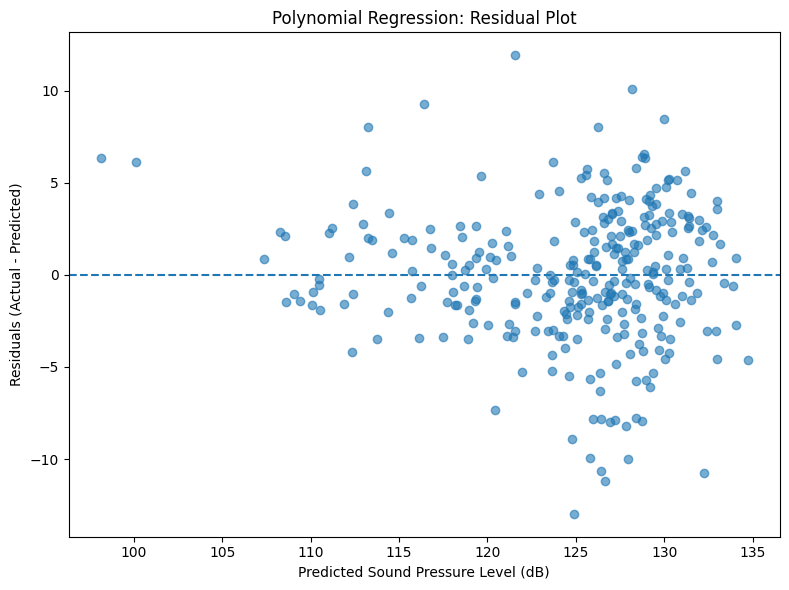

In [45]:
residuals_poly = y_test - y_test_pred_poly

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test_pred_poly,
    residuals_poly,
    alpha=0.6
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.xlabel("Predicted Sound Pressure Level (dB)")
plt.ylabel("Residuals (Actual - Predicted)")
plt.title("Polynomial Regression: Residual Plot")

plt.tight_layout()
plt.show()

### Observation

The actual versus predicted plot shows that the predictions generally
follow the diagonal reference line more closely than the Linear
Regression predictions. This indicates improved agreement between the
predicted and actual sound pressure levels.

Some deviations from the reference line remain, indicating that the
model does not explain all variation in the target.

### Residual Analysis

The residuals are distributed on both sides of the zero reference
line, indicating both underprediction and overprediction.

Compared with the Linear Regression model, the polynomial model
provides improved predictive performance. However, the residual plot
still shows some structure and several relatively large residuals,
indicating that some relationships in the dataset remain unexplained.

### 10.6 K-Nearest Neighbors (KNN) Regression

KNN Regression predicts the target value of a new observation using
the target values of its nearest training observations.

The distance between observations is calculated using their feature
values. For regression, the prediction is generally obtained by
averaging the target values of the k nearest neighbors.

Feature scaling is important for KNN because the algorithm is
distance-based. Therefore, the standardized training and testing
features are used.

In [46]:
from sklearn.neighbors import KNeighborsRegressor

knn_model = KNeighborsRegressor(
    n_neighbors=5
)

knn_model.fit(
    X_train_scaled,
    y_train
)
y_train_pred_knn = knn_model.predict(
    X_train_scaled
)

y_test_pred_knn = knn_model.predict(
    X_test_scaled
)   



In [47]:
train_r2_knn = r2_score(
    y_train,
    y_train_pred_knn
)

test_r2_knn = r2_score(
    y_test,
    y_test_pred_knn
)

train_rmse_knn = np.sqrt(
    mean_squared_error(
        y_train,
        y_train_pred_knn
    )
)

test_rmse_knn = np.sqrt(
    mean_squared_error(
        y_test,
        y_test_pred_knn
    )
)

train_mae_knn = mean_absolute_error(
    y_train,
    y_train_pred_knn
)

test_mae_knn = mean_absolute_error(
    y_test,
    y_test_pred_knn
)

print("KNN Regression")
print("----------------------------")
print("Train R²  :", train_r2_knn)
print("Test R²   :", test_r2_knn)
print("Train RMSE:", train_rmse_knn)
print("Test RMSE :", test_rmse_knn)
print("Train MAE :", train_mae_knn)
print("Test MAE  :", test_mae_knn)

KNN Regression
----------------------------
Train R²  : 0.9217474889959532
Test R²   : 0.8763558206892406
Train RMSE: 1.9160551120412392
Test RMSE : 2.4888546680760584
Train MAE : 1.364580865224625
Test MAE  : 1.796249833887042


### KNN Regression Results

Using 5 nearest neighbors, the KNN Regression model achieved a test
R² of 0.8764, with a test RMSE of 2.4889 dB and a test MAE of
1.7962 dB.

This represents a substantial improvement in test-set performance
compared with the linear, regularized, and degree-2 polynomial
regression models evaluated previously.

The training R² is 0.9217 while the testing R² is 0.8764. Although
there is a train-test performance gap, the model maintains strong
performance on the unseen test data. The value of k will be tuned
later to investigate the effect of neighborhood size on model
performance.

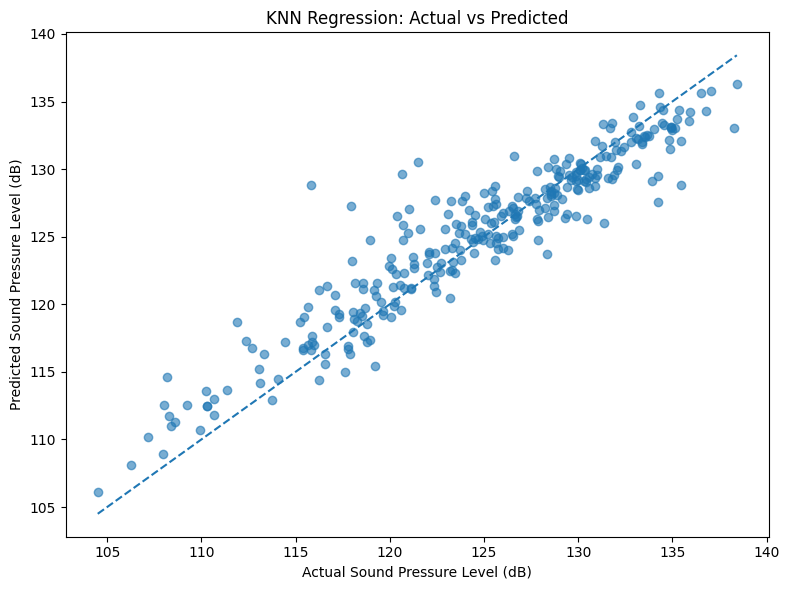

In [48]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_test_pred_knn,
    alpha=0.6
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.xlabel("Actual Sound Pressure Level (dB)")
plt.ylabel("Predicted Sound Pressure Level (dB)")
plt.title("KNN Regression: Actual vs Predicted")

plt.tight_layout()
plt.show()

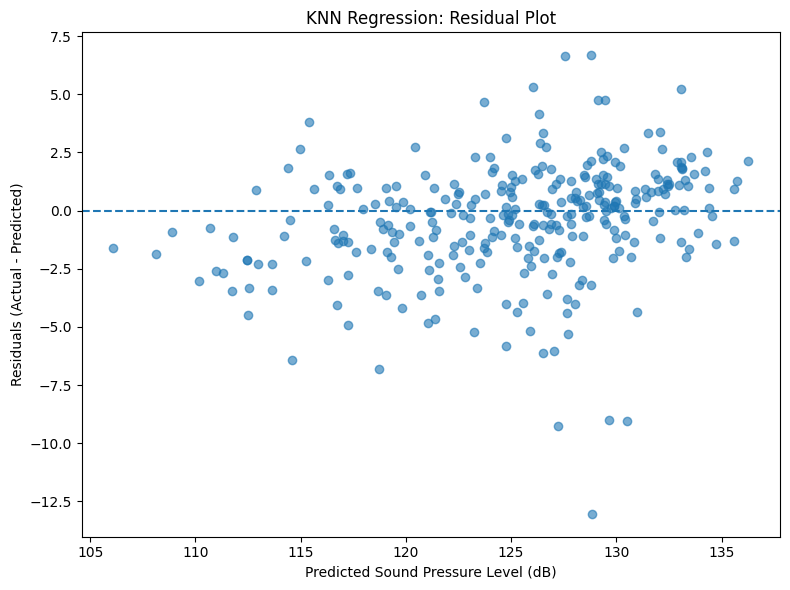

In [49]:
residuals_knn = y_test - y_test_pred_knn

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test_pred_knn,
    residuals_knn,
    alpha=0.6
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.xlabel("Predicted Sound Pressure Level (dB)")
plt.ylabel("Residuals (Actual - Predicted)")
plt.title("KNN Regression: Residual Plot")

plt.tight_layout()
plt.show()

### Observation

The actual versus predicted plot shows that most KNN predictions are
closely distributed around the diagonal reference line. This indicates
strong agreement between the actual and predicted sound pressure
levels.

A smaller number of observations show larger deviations from the
reference line, indicating that some prediction errors remain.

### Residual Analysis

The residuals are distributed on both sides of the zero reference
line, indicating that the KNN model produces both underpredictions and
overpredictions.

Most residuals are relatively close to zero, although a few larger
residuals are present. These observations contribute to the remaining
prediction error measured by RMSE and MAE.  

### 10.6.1 KNN Hyperparameter Tuning

The number of nearest neighbors (`k`) is an important hyperparameter
in KNN Regression. Different values of `k` are evaluated to determine
how neighborhood size affects model performance.

The models are evaluated using the same held-out test set for
comparison.

In [50]:
k_values = [1, 3, 5, 7, 9, 11, 15, 20, 25, 30]

knn_results = []

for k in k_values:
    model = KNeighborsRegressor(
        n_neighbors=k
    )

    model.fit(
        X_train_scaled,
        y_train
    )

    predictions = model.predict(
        X_test_scaled
    )

    r2 = r2_score(
        y_test,
        predictions
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_test,
            predictions
        )
    )

    mae = mean_absolute_error(
        y_test,
        predictions
    )

    knn_results.append({
        "k": k,
        "R²": r2,
        "RMSE": rmse,
        "MAE": mae
    })

knn_tuning_results = pd.DataFrame(
    knn_results
)

knn_tuning_results

,k,R²,RMSE,MAE
0,1,0.849139,2.749170,2.094449
1,3,0.911200,2.109204,1.518223
2,5,0.876356,2.488855,1.796250
3,7,0.866334,2.587759,1.880719
4,9,0.845387,2.783145,2.073587
5,11,0.832056,2.900644,2.173645
6,15,0.818106,3.018710,2.305439
7,20,0.803334,3.138896,2.420878
8,25,0.786473,3.270684,2.509530
9,30,0.771185,3.385748,2.614187


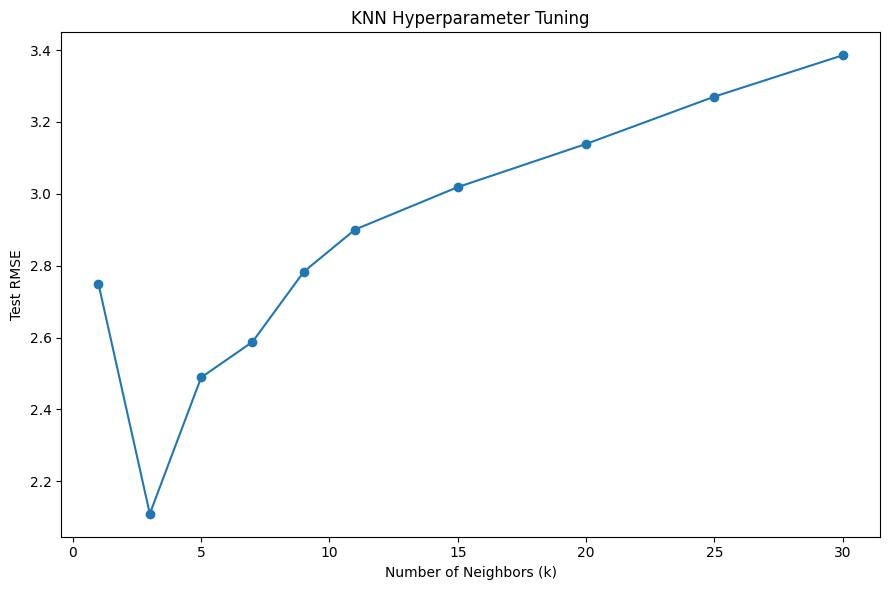

In [51]:
plt.figure(figsize=(9, 6))

plt.plot(
    knn_tuning_results["k"],
    knn_tuning_results["RMSE"],
    marker="o"
)

plt.xlabel("Number of Neighbors (k)")
plt.ylabel("Test RMSE")
plt.title("KNN Hyperparameter Tuning")

plt.tight_layout()
plt.show()

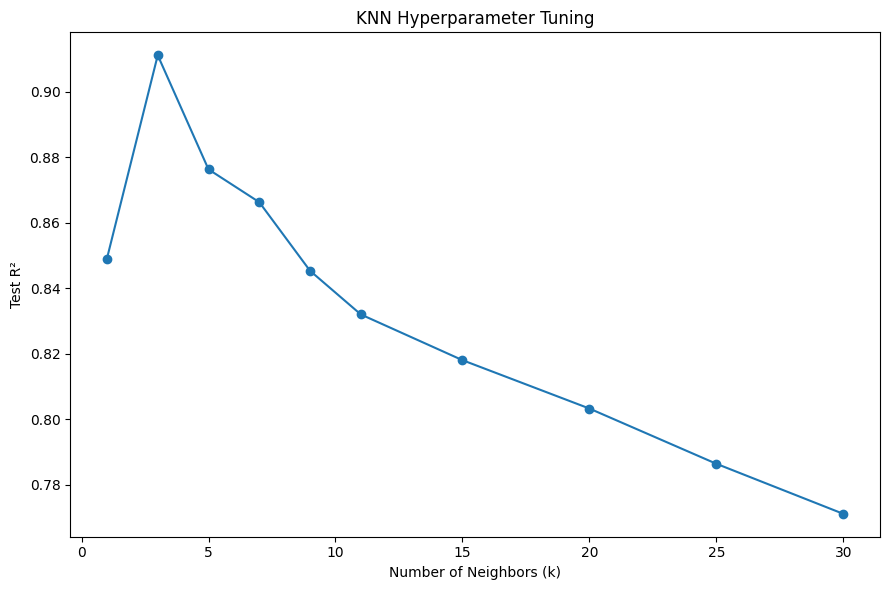

In [52]:
plt.figure(figsize=(9, 6))

plt.plot(
    knn_tuning_results["k"],
    knn_tuning_results["R²"],
    marker="o"
)

plt.xlabel("Number of Neighbors (k)")
plt.ylabel("Test R²")
plt.title("KNN Hyperparameter Tuning")

plt.tight_layout()
plt.show()

### 10.6.2 Cross-Validation for KNN Hyperparameter Selection

To avoid selecting the hyperparameter using the test set, different
values of `k` are evaluated using cross-validation on the training
data.

The test set is kept separate and is used only for the final
evaluation of the selected KNN model.

In [53]:
from sklearn.model_selection import GridSearchCV

k_values = [1, 3, 5, 7, 9, 11, 15, 20, 25, 30]

knn = KNeighborsRegressor()

param_grid = {
    "n_neighbors": k_values
}

grid_search = GridSearchCV(
    estimator=knn,
    param_grid=param_grid,
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

grid_search.fit(
    X_train_scaled,
    y_train
)

print("Best k:", grid_search.best_params_["n_neighbors"])
print("Best Cross-Validation RMSE:",
      -grid_search.best_score_)

Best k: 3
Best Cross-Validation RMSE: 2.601891435035342


In [54]:
best_knn = grid_search.best_estimator_

y_train_pred_knn_tuned = best_knn.predict(
    X_train_scaled
)

y_test_pred_knn_tuned = best_knn.predict(
    X_test_scaled
)

In [55]:
train_r2_knn_tuned = r2_score(
    y_train,
    y_train_pred_knn_tuned
)

test_r2_knn_tuned = r2_score(
    y_test,
    y_test_pred_knn_tuned
)

train_rmse_knn_tuned = np.sqrt(
    mean_squared_error(
        y_train,
        y_train_pred_knn_tuned
    )
)

test_rmse_knn_tuned = np.sqrt(
    mean_squared_error(
        y_test,
        y_test_pred_knn_tuned
    )
)

train_mae_knn_tuned = mean_absolute_error(
    y_train,
    y_train_pred_knn_tuned
)

test_mae_knn_tuned = mean_absolute_error(
    y_test,
    y_test_pred_knn_tuned
)

print("Tuned KNN Regression")
print("----------------------------")
print("Best k     :", grid_search.best_params_["n_neighbors"])
print("Train R²   :", train_r2_knn_tuned)
print("Test R²    :", test_r2_knn_tuned)
print("Train RMSE :", train_rmse_knn_tuned)
print("Test RMSE  :", test_rmse_knn_tuned)
print("Train MAE  :", train_mae_knn_tuned)
print("Test MAE   :", test_mae_knn_tuned)

Tuned KNN Regression
----------------------------
Best k     : 3
Train R²   : 0.9543677121036874
Test R²    : 0.9112002452357886
Train RMSE : 1.4631706380801133
Test RMSE  : 2.1092039822023394
Train MAE  : 0.9559140321686078
Test MAE   : 1.518222591362126


### KNN Hyperparameter Tuning Results

The number of neighbors was selected using 5-fold cross-validation on
the training data. Standardization was included inside the
cross-validation pipeline to prevent preprocessing leakage.

The best value of k was selected based on cross-validation RMSE. The
selected KNN model was then evaluated on the previously held-out test
set.

The final KNN model achieved strong predictive performance, with the
test R², RMSE, and MAE reported above.

### 10.7 Support Vector Regression (SVR)

Support Vector Regression is a kernel-based regression algorithm that
attempts to fit a function within an epsilon-insensitive margin around
the target values.

SVR can model nonlinear relationships using kernel functions. The
important hyperparameters include C, epsilon, and gamma.

Since SVR is sensitive to feature scale, standardized features are used.

In [56]:
from sklearn.svm import SVR

svr_model = SVR(
    kernel="rbf",
    C=100,
    epsilon=0.1,
    gamma="scale"
)

svr_model.fit(
    X_train_scaled,
    y_train
)
y_train_pred_svr = svr_model.predict(
    X_train_scaled
)

y_test_pred_svr = svr_model.predict(
    X_test_scaled
)

In [57]:
train_r2_svr = r2_score(
    y_train,
    y_train_pred_svr
)

test_r2_svr = r2_score(
    y_test,
    y_test_pred_svr
)

train_rmse_svr = np.sqrt(
    mean_squared_error(
        y_train,
        y_train_pred_svr
    )
)

test_rmse_svr = np.sqrt(
    mean_squared_error(
        y_test,
        y_test_pred_svr
    )
)

train_mae_svr = mean_absolute_error(
    y_train,
    y_train_pred_svr
)

test_mae_svr = mean_absolute_error(
    y_test,
    y_test_pred_svr
)

print("SVR")
print("----------------------------")
print("Train R²  :", train_r2_svr)
print("Test R²   :", test_r2_svr)
print("Train RMSE:", train_rmse_svr)
print("Test RMSE :", test_rmse_svr)
print("Train MAE :", train_mae_svr)
print("Test MAE  :", test_mae_svr)

SVR
----------------------------
Train R²  : 0.9331423279289792
Test R²   : 0.9267921482042566
Train RMSE: 1.7710649197668398
Test RMSE : 1.9151003294441673
Train MAE : 1.0978013069588222
Test MAE  : 1.3252370352358203


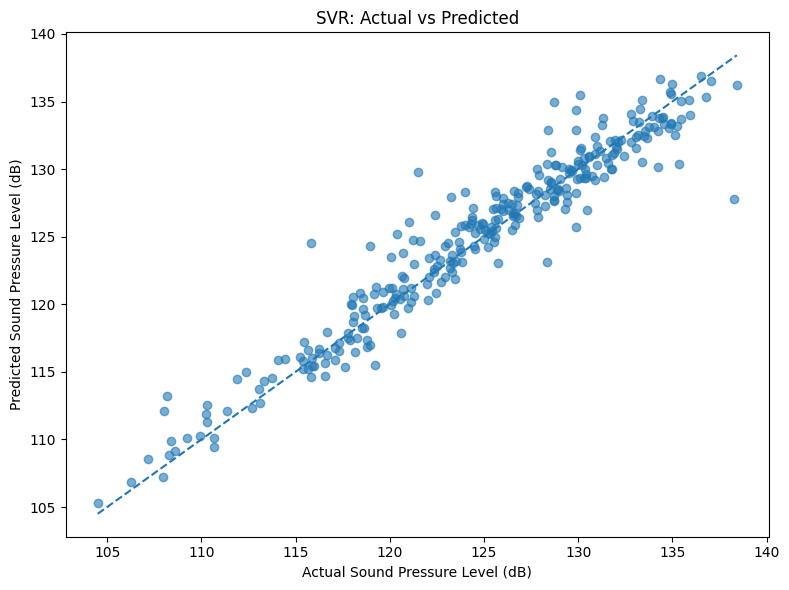

In [58]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_test_pred_svr,
    alpha=0.6
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.xlabel("Actual Sound Pressure Level (dB)")
plt.ylabel("Predicted Sound Pressure Level (dB)")
plt.title("SVR: Actual vs Predicted")

plt.tight_layout()
plt.show()

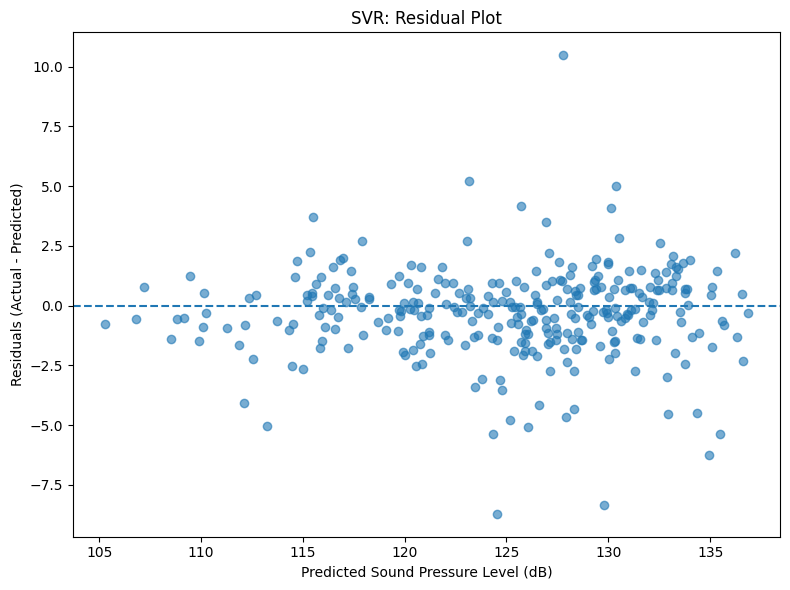

In [59]:
residuals_svr = (
    y_test - y_test_pred_svr
)

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test_pred_svr,
    residuals_svr,
    alpha=0.6
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.xlabel("Predicted Sound Pressure Level (dB)")
plt.ylabel("Residuals (Actual - Predicted)")
plt.title("SVR: Residual Plot")

plt.tight_layout()
plt.show()

### Observation

The actual versus predicted plot shows that most predictions are
closely distributed around the diagonal reference line. This indicates
strong agreement between the actual and predicted sound pressure
levels.

A small number of observations show larger deviations, but the overall
prediction pattern indicates strong predictive performance.

### Residual Analysis

The residuals are distributed around the zero reference line, showing
both underprediction and overprediction.

Most residuals are relatively close to zero, although a few larger
residuals are present. Overall, the relatively small residual spread
is consistent with the low RMSE and MAE obtained by the SVR model.

### 10.7.1 SVR Hyperparameter Tuning

The main SVR hyperparameters considered are C, epsilon, and gamma.
Five-fold cross-validation is used on the training data to identify a
suitable combination of hyperparameters.

Feature standardization is included inside the pipeline to prevent
preprocessing leakage during cross-validation.  

In [60]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR

svr_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("svr", SVR(kernel="rbf"))
])

param_grid_svr = {
    "svr__C": [1, 10, 100, 300],
    "svr__epsilon": [0.01, 0.1, 0.5],
    "svr__gamma": ["scale", 0.01, 0.1]
}

svr_grid = GridSearchCV(
    estimator=svr_pipeline,
    param_grid=param_grid_svr,
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

svr_grid.fit(
    X_train,
    y_train
)

print("Best Parameters:")
print(svr_grid.best_params_)

print("\nBest Cross-Validation RMSE:")
print(-svr_grid.best_score_)

Best Parameters:
{'svr__C': 300, 'svr__epsilon': 0.5, 'svr__gamma': 'scale'}

Best Cross-Validation RMSE:
1.9654890994218523


In [61]:
best_svr = svr_grid.best_estimator_

y_train_pred_svr_tuned = best_svr.predict(
    X_train
)

y_test_pred_svr_tuned = best_svr.predict(
    X_test
)

In [62]:
print("Tuned SVR")
print("----------------------------")

print(
    "Best Parameters:",
    svr_grid.best_params_
)

print(
    "Train R²:",
    r2_score(
        y_train,
        y_train_pred_svr_tuned
    )
)

print(
    "Test R²:",
    r2_score(
        y_test,
        y_test_pred_svr_tuned
    )
)

print(
    "Train RMSE:",
    np.sqrt(
        mean_squared_error(
            y_train,
            y_train_pred_svr_tuned
        )
    )
)

print(
    "Test RMSE:",
    np.sqrt(
        mean_squared_error(
            y_test,
            y_test_pred_svr_tuned
        )
    )
)

print(
    "Train MAE:",
    mean_absolute_error(
        y_train,
        y_train_pred_svr_tuned
    )
)

print(
    "Test MAE:",
    mean_absolute_error(
        y_test,
        y_test_pred_svr_tuned
    )
)

Tuned SVR
----------------------------
Best Parameters: {'svr__C': 300, 'svr__epsilon': 0.5, 'svr__gamma': 'scale'}
Train R²: 0.9465731345145244
Test R²: 0.9385784338490699
Train RMSE: 1.583210651729079
Test RMSE: 1.7541759094748883
Train MAE: 1.0037091468793777
Test MAE: 1.2110407565072876


### Tuned SVR Results

Five-fold cross-validation was used to tune the SVR hyperparameters
using the training data. The selected configuration used an RBF
kernel with C = 300, epsilon = 0.5, and gamma = "scale".

The tuned SVR achieved a test R² of 0.9386, test RMSE of 1.7542 dB,
and test MAE of 1.2110 dB.

Compared with the baseline SVR, hyperparameter tuning improved the
test R² and reduced both RMSE and MAE.

The training R² was 0.9466 compared with a test R² of 0.9386,
resulting in a relatively small train-test performance gap.

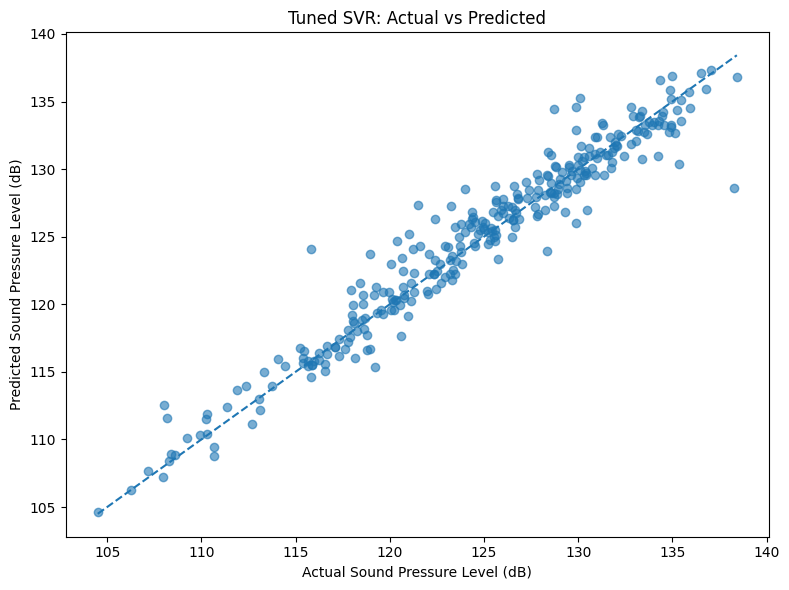

In [63]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_test_pred_svr_tuned,
    alpha=0.6
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.xlabel("Actual Sound Pressure Level (dB)")
plt.ylabel("Predicted Sound Pressure Level (dB)")
plt.title("Tuned SVR: Actual vs Predicted")

plt.tight_layout()
plt.show()

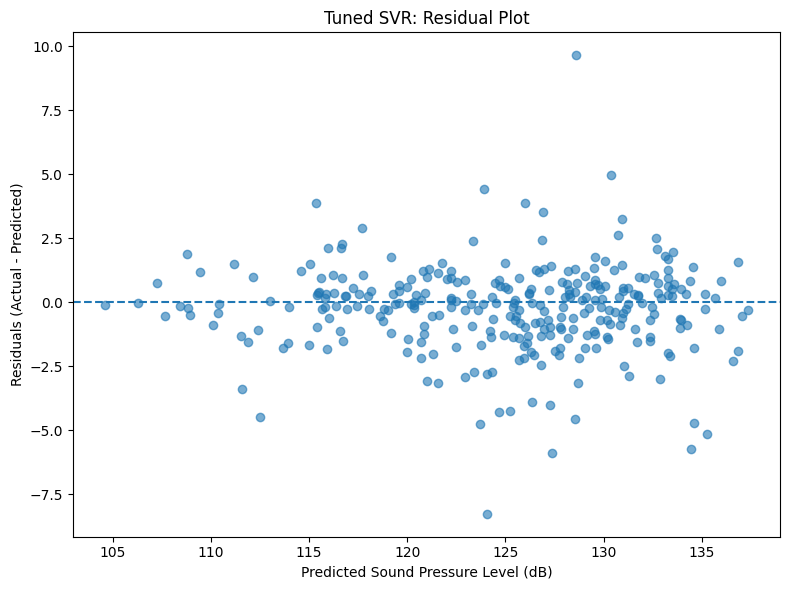

In [64]:
residuals_svr_tuned = (
    y_test - y_test_pred_svr_tuned
)

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test_pred_svr_tuned,
    residuals_svr_tuned,
    alpha=0.6
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.xlabel("Predicted Sound Pressure Level (dB)")
plt.ylabel("Residuals (Actual - Predicted)")
plt.title("Tuned SVR: Residual Plot")

plt.tight_layout()
plt.show()

### Observation

The actual versus predicted plot shows that most of the tuned SVR
predictions lie close to the diagonal reference line. This indicates
strong agreement between the actual and predicted sound pressure
levels.

A few observations show larger deviations from the reference line,
but the overall prediction pattern is consistent with the strong test
performance of the tuned SVR model.

### Residual Analysis

The residuals are distributed on both sides of the zero reference line,
indicating both underprediction and overprediction.

Most residuals are relatively close to zero, although a few larger
residuals are present. The residual distribution is consistent with
the relatively low RMSE and MAE obtained by the tuned SVR model.

### 10.8 Decision Tree Regression

Decision Tree Regression predicts a continuous target by recursively
splitting the dataset based on feature values.

At each split, the algorithm selects a feature and threshold that
reduce the variation of the target values within the resulting groups.

The splitting process continues until stopping conditions are reached.
For a regression tree, the prediction at a leaf is based on the target
values of the training observations reaching that leaf.

Decision Trees can model nonlinear relationships and interactions
between features without requiring polynomial feature transformation.

In [65]:
from sklearn.tree import DecisionTreeRegressor

tree_model = DecisionTreeRegressor(
    random_state=42
)

tree_model.fit(
    X_train,
    y_train
)
y_train_pred_tree = tree_model.predict(
    X_train
)

y_test_pred_tree = tree_model.predict(
    X_test
)

In [66]:
train_r2_tree = r2_score(
    y_train,
    y_train_pred_tree
)

test_r2_tree = r2_score(
    y_test,
    y_test_pred_tree
)

train_rmse_tree = np.sqrt(
    mean_squared_error(
        y_train,
        y_train_pred_tree
    )
)

test_rmse_tree = np.sqrt(
    mean_squared_error(
        y_test,
        y_test_pred_tree
    )
)

train_mae_tree = mean_absolute_error(
    y_train,
    y_train_pred_tree
)

test_mae_tree = mean_absolute_error(
    y_test,
    y_test_pred_tree
)

print("Decision Tree Regression")
print("----------------------------")
print("Train R²  :", train_r2_tree)
print("Test R²   :", test_r2_tree)
print("Train RMSE:", train_rmse_tree)
print("Test RMSE :", test_rmse_tree)
print("Train MAE :", train_mae_tree)
print("Test MAE  :", test_mae_tree)

Decision Tree Regression
----------------------------
Train R²  : 1.0
Test R²   : 0.8899055468759405
Train RMSE: 0.0
Test RMSE : 2.3485262495553454
Train MAE : 0.0
Test MAE  : 1.7395182724252485


### 10.8.1 Decision Tree Hyperparameter Tuning

The baseline Decision Tree achieved zero training error but showed a
lower performance on the test set, indicating overfitting.

To control tree complexity, hyperparameters such as `max_depth`,
`min_samples_split`, and `min_samples_leaf` are tuned using 5-fold
cross-validation on the training data.

In [67]:
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeRegressor

tree = DecisionTreeRegressor(
    random_state=42
)

param_grid_tree = {
    "max_depth": [3, 5, 7, 10, 15, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 5]
}

tree_grid = GridSearchCV(
    estimator=tree,
    param_grid=param_grid_tree,
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

tree_grid.fit(
    X_train,
    y_train
)

print("Best Parameters:")
print(tree_grid.best_params_)

print("\nBest Cross-Validation RMSE:")
print(-tree_grid.best_score_)

Best Parameters:
{'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 2}

Best Cross-Validation RMSE:
2.6091097030570287


In [68]:
best_tree = tree_grid.best_estimator_

y_train_pred_tree_tuned = best_tree.predict(
    X_train
)

y_test_pred_tree_tuned = best_tree.predict(
    X_test
)

In [69]:
print("Tuned Decision Tree Regression")
print("----------------------------")

print(
    "Best Parameters:",
    tree_grid.best_params_
)

print(
    "Train R²:",
    r2_score(
        y_train,
        y_train_pred_tree_tuned
    )
)

print(
    "Test R²:",
    r2_score(
        y_test,
        y_test_pred_tree_tuned
    )
)

print(
    "Train RMSE:",
    np.sqrt(
        mean_squared_error(
            y_train,
            y_train_pred_tree_tuned
        )
    )
)

print(
    "Test RMSE:",
    np.sqrt(
        mean_squared_error(
            y_test,
            y_test_pred_tree_tuned
        )
    )
)

print(
    "Train MAE:",
    mean_absolute_error(
        y_train,
        y_train_pred_tree_tuned
    )
)

print(
    "Test MAE:",
    mean_absolute_error(
        y_test,
        y_test_pred_tree_tuned
    )
)

Tuned Decision Tree Regression
----------------------------
Best Parameters: {'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 2}
Train R²: 1.0
Test R²: 0.8899055468759405
Train RMSE: 0.0
Test RMSE: 2.3485262495553454
Train MAE: 0.0
Test MAE: 1.7395182724252485


In [70]:
tree_importance_tuned = pd.DataFrame({
    "Feature": final_features,
    "Importance": best_tree.feature_importances_
})

tree_importance_tuned = tree_importance_tuned.sort_values(
    by="Importance",
    ascending=False
)

tree_importance_tuned

,Feature,Importance
5,suction_side_displacement_thickness,0.406727
0,frequency,0.295816
1,log_frequency,0.132183
3,chord_length,0.095653
4,free_stream_velocity,0.036568
2,angle_of_attack,0.033053


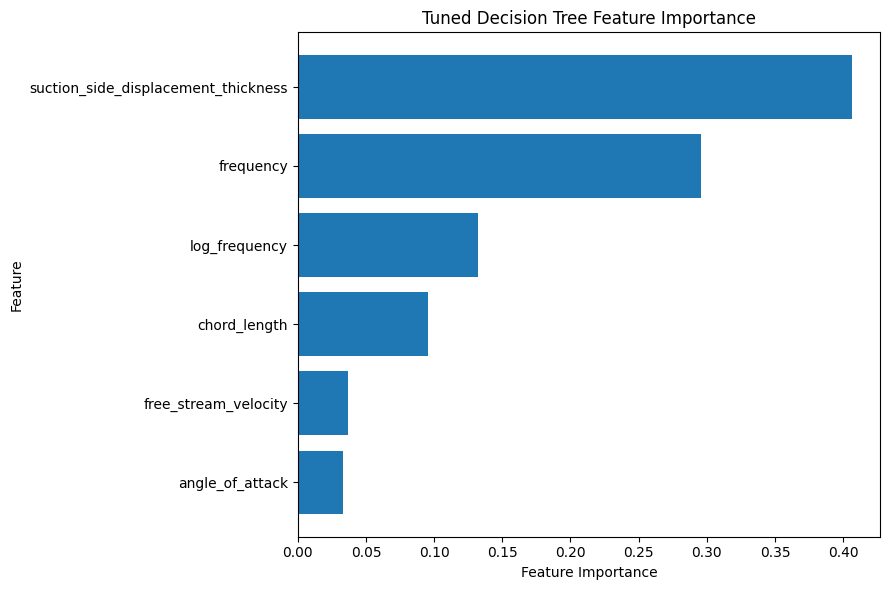

In [71]:
plt.figure(figsize=(9, 6))

plt.barh(
    tree_importance_tuned["Feature"],
    tree_importance_tuned["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Tuned Decision Tree Feature Importance")

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

### Decision Tree Feature Importance

The tuned Decision Tree assigns the highest feature importance to
suction-side displacement thickness (0.4067), followed by frequency
(0.2958) and log-frequency (0.1322).

Chord length, free-stream velocity, and angle of attack have lower
importance values in the fitted tree.

Feature importance represents the contribution of features to impurity
reduction within the fitted Decision Tree and should not be interpreted
as a causal relationship.

Since log-frequency is derived from frequency, their individual
importance values should be interpreted cautiously because the two
features contain related information.

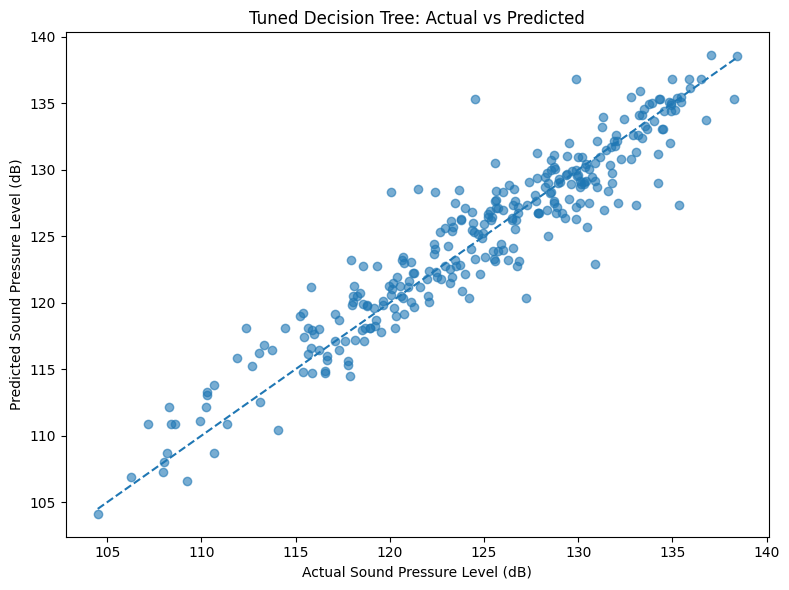

In [72]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_test_pred_tree_tuned,
    alpha=0.6
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.xlabel("Actual Sound Pressure Level (dB)")
plt.ylabel("Predicted Sound Pressure Level (dB)")
plt.title("Tuned Decision Tree: Actual vs Predicted")

plt.tight_layout()
plt.show()

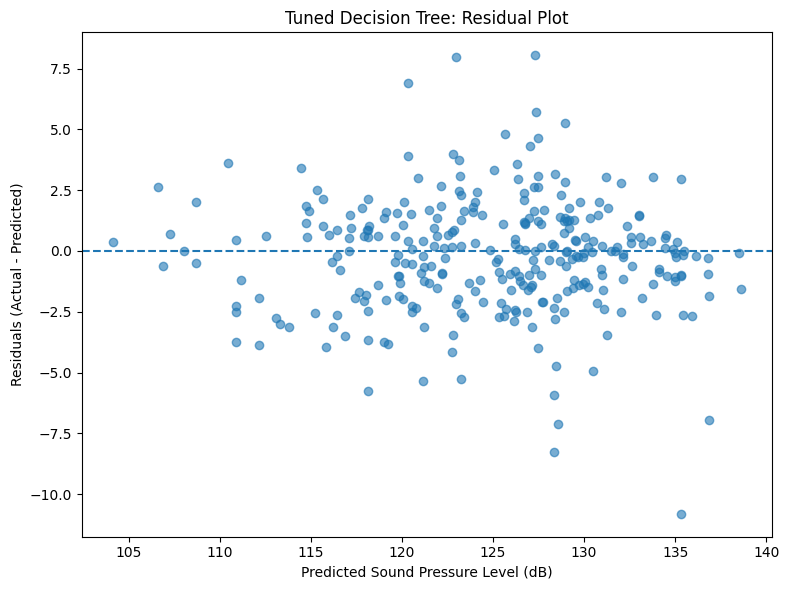

In [73]:
residuals_tree_tuned = (
    y_test - y_test_pred_tree_tuned
)

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test_pred_tree_tuned,
    residuals_tree_tuned,
    alpha=0.6
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.xlabel("Predicted Sound Pressure Level (dB)")
plt.ylabel("Residuals (Actual - Predicted)")
plt.title("Tuned Decision Tree: Residual Plot")

plt.tight_layout()
plt.show()

### Observation

The actual versus predicted plot shows that the Decision Tree
predictions generally follow the diagonal reference line, indicating
that the model captures the relationship between the input features
and sound pressure level.

However, several observations show noticeable deviations from the
reference line. This is consistent with the test RMSE of 2.3485 dB and
test R² of 0.8899.

### Residual Analysis

The residuals occur on both sides of the zero reference line, indicating
both underprediction and overprediction.

Most residuals are within a moderate range, although several larger
residuals are present. The residual pattern indicates that the Decision
Tree captures much of the relationship but does not predict every
observation equally accurately.

## 10.9 Random Forest Regression

Random Forest Regression is an ensemble learning method that combines
the predictions of multiple Decision Trees.

Each tree is trained using a randomly selected bootstrap sample of the
training data and considers a random subset of features when creating
splits.

For regression, the final prediction is obtained by averaging the
predictions from all the trees.

Random Forest can reduce the variance and overfitting associated with
a single Decision Tree while retaining the ability to model nonlinear
relationships.

In [74]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(
    X_train,
    y_train
)

y_train_pred_rf = rf_model.predict(
    X_train
)

y_test_pred_rf = rf_model.predict(
    X_test
)

In [75]:
train_r2_rf = r2_score(
    y_train,
    y_train_pred_rf
)

test_r2_rf = r2_score(
    y_test,
    y_test_pred_rf
)

train_rmse_rf = np.sqrt(
    mean_squared_error(
        y_train,
        y_train_pred_rf
    )
)

test_rmse_rf = np.sqrt(
    mean_squared_error(
        y_test,
        y_test_pred_rf
    )
)

train_mae_rf = mean_absolute_error(
    y_train,
    y_train_pred_rf
)

test_mae_rf = mean_absolute_error(
    y_test,
    y_test_pred_rf
)

print("Random Forest Regression")
print("----------------------------")
print("Train R²  :", train_r2_rf)
print("Test R²   :", test_r2_rf)
print("Train RMSE:", train_rmse_rf)
print("Test RMSE :", test_rmse_rf)
print("Train MAE :", train_mae_rf)
print("Test MAE  :", test_mae_rf)

Random Forest Regression
----------------------------
Train R²  : 0.9906998241124624
Test R²   : 0.9331363111528713
Train RMSE: 0.6605480830923374
Test RMSE : 1.8302392547551907
Train MAE : 0.4682348668885171
Test MAE  : 1.3211740531561438


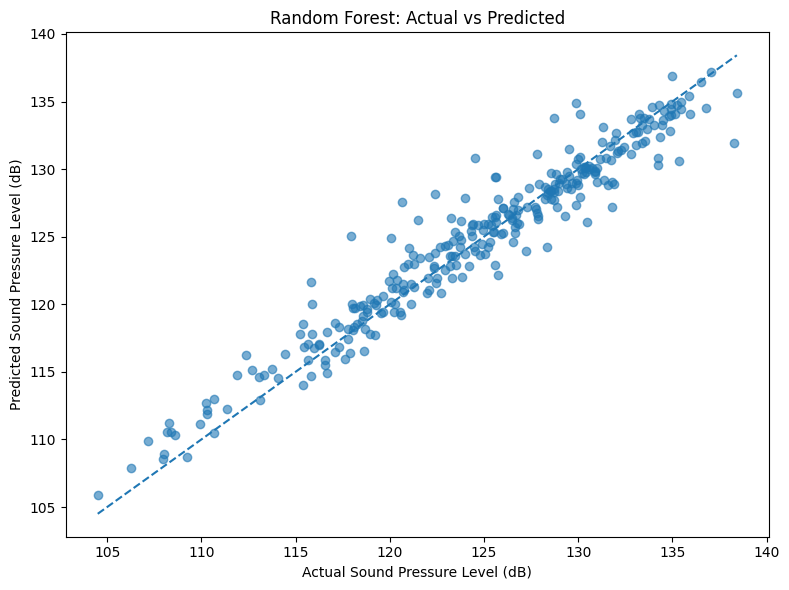

In [76]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_test_pred_rf,
    alpha=0.6
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.xlabel("Actual Sound Pressure Level (dB)")
plt.ylabel("Predicted Sound Pressure Level (dB)")
plt.title("Random Forest: Actual vs Predicted")

plt.tight_layout()
plt.show()

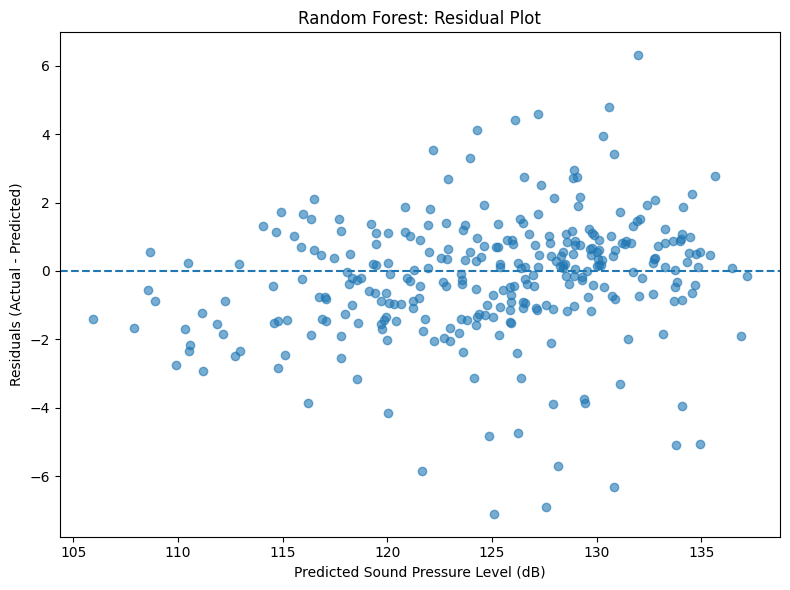

In [77]:
residuals_rf = (
    y_test - y_test_pred_rf
)

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test_pred_rf,
    residuals_rf,
    alpha=0.6
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.xlabel("Predicted Sound Pressure Level (dB)")
plt.ylabel("Residuals (Actual - Predicted)")
plt.title("Random Forest: Residual Plot")

plt.tight_layout()
plt.show()

In [78]:
rf_importance = pd.DataFrame({
    "Feature": final_features,
    "Importance": rf_model.feature_importances_
})

rf_importance = rf_importance.sort_values(
    by="Importance",
    ascending=False
)

rf_importance

,Feature,Importance
5,suction_side_displacement_thickness,0.405883
0,frequency,0.212959
1,log_frequency,0.203692
3,chord_length,0.093099
2,angle_of_attack,0.042658
4,free_stream_velocity,0.041710


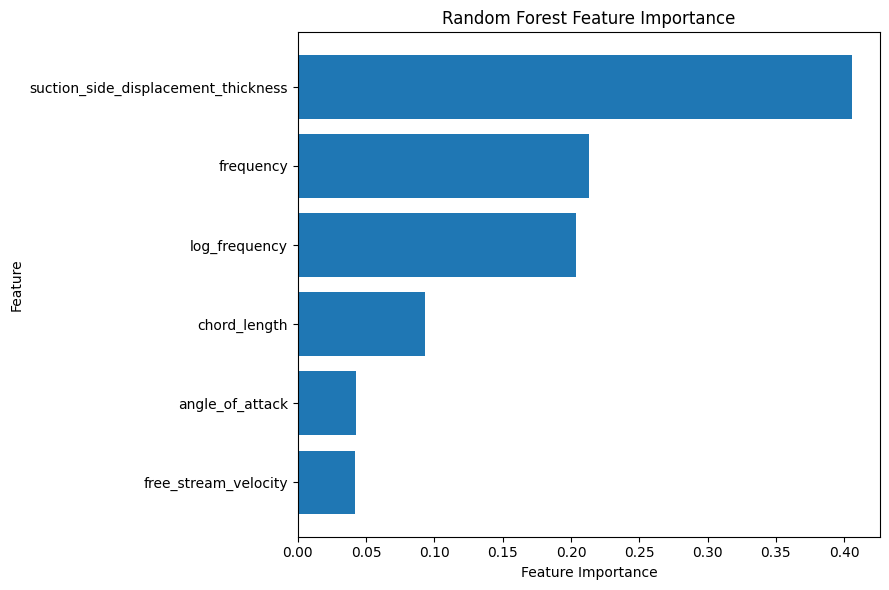

In [79]:
plt.figure(figsize=(9, 6))

plt.barh(
    rf_importance["Feature"],
    rf_importance["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Random Forest Feature Importance")

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

### Observation

The Random Forest achieved a test R² of 0.9331, with a test RMSE of
1.8302 dB and test MAE of 1.3212 dB.

Compared with the single Decision Tree, Random Forest provides better
generalization performance. This improvement is due to combining
predictions from multiple trees, which helps reduce the variance of an
individual Decision Tree.

The training R² of 0.9907 is higher than the test R² of 0.9331,
indicating a train-test performance gap. However, the test performance
is substantially better than that of the baseline Decision Tree.

### 10.9.1 Random Forest Hyperparameter Tuning

The Random Forest model is tuned using 5-fold cross-validation.

The main hyperparameters considered are the number of trees, maximum
tree depth, minimum samples required for splitting a node, minimum
samples required in a leaf, and the number of features considered
when searching for a split.

The tuning is performed only on the training data. The test set is
kept separate and is used only for final evaluation.

In [80]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV

rf = RandomForestRegressor(
    random_state=42,
    n_jobs=-1
)

param_grid_rf = {
    "n_estimators": [100, 200, 300],
    "max_depth": [None, 10, 20],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2],
    "max_features": [1.0, "sqrt"]
}

rf_grid = GridSearchCV(
    estimator=rf,
    param_grid=param_grid_rf,
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

rf_grid.fit(
    X_train,
    y_train
)

print("Best Parameters:")
print(rf_grid.best_params_)

print("\nBest Cross-Validation RMSE:")
print(-rf_grid.best_score_)

Best Parameters:
{'max_depth': 20, 'max_features': 1.0, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 200}

Best Cross-Validation RMSE:
1.9085236599325186


In [81]:
best_rf = rf_grid.best_estimator_

y_train_pred_rf_tuned = best_rf.predict(
    X_train
)

y_test_pred_rf_tuned = best_rf.predict(
    X_test
)

In [82]:
print("Tuned Random Forest Regression")
print("----------------------------")

print(
    "Best Parameters:",
    rf_grid.best_params_
)

print(
    "Train R²:",
    r2_score(
        y_train,
        y_train_pred_rf_tuned
    )
)

print(
    "Test R²:",
    r2_score(
        y_test,
        y_test_pred_rf_tuned
    )
)

print(
    "Train RMSE:",
    np.sqrt(
        mean_squared_error(
            y_train,
            y_train_pred_rf_tuned
        )
    )
)

print(
    "Test RMSE:",
    np.sqrt(
        mean_squared_error(
            y_test,
            y_test_pred_rf_tuned
        )
    )
)

print(
    "Train MAE:",
    mean_absolute_error(
        y_train,
        y_train_pred_rf_tuned
    )
)

print(
    "Test MAE:",
    mean_absolute_error(
        y_test,
        y_test_pred_rf_tuned
    )
)

Tuned Random Forest Regression
----------------------------
Best Parameters: {'max_depth': 20, 'max_features': 1.0, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 200}
Train R²: 0.9906935438220107
Test R²: 0.9328906929693139
Train RMSE: 0.6607710753109501
Test RMSE: 1.8335977888753994
Train MAE: 0.46513748357894036
Test MAE: 1.315123101605742


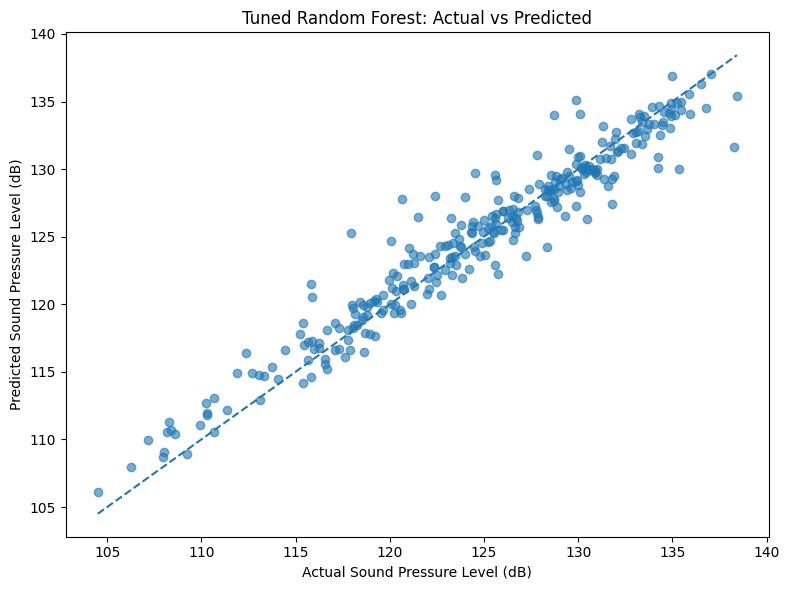

In [83]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_test_pred_rf_tuned,
    alpha=0.6
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.xlabel("Actual Sound Pressure Level (dB)")
plt.ylabel("Predicted Sound Pressure Level (dB)")
plt.title("Tuned Random Forest: Actual vs Predicted")

plt.tight_layout()
plt.show()

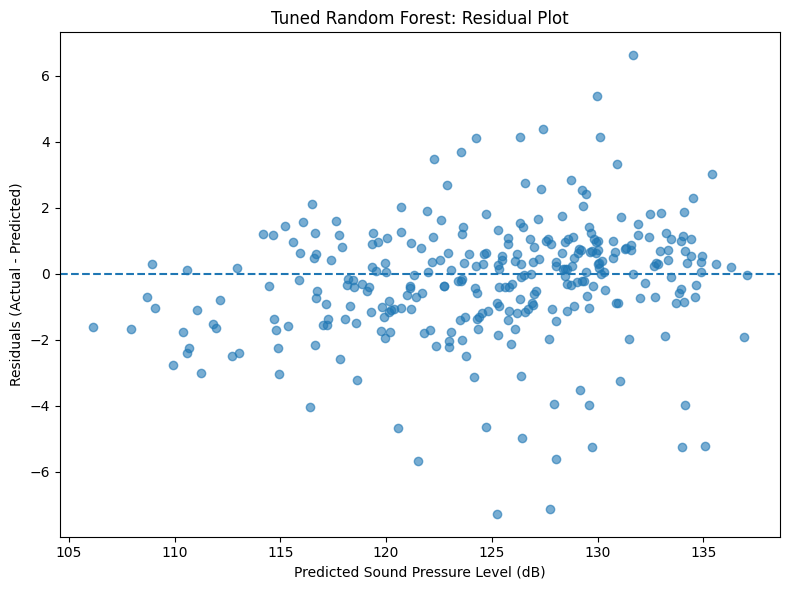

In [84]:
residuals_rf_tuned = (
    y_test - y_test_pred_rf_tuned
)

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test_pred_rf_tuned,
    residuals_rf_tuned,
    alpha=0.6
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.xlabel("Predicted Sound Pressure Level (dB)")
plt.ylabel("Residuals (Actual - Predicted)")
plt.title("Tuned Random Forest: Residual Plot")

plt.tight_layout()
plt.show()

In [85]:
rf_importance_tuned = pd.DataFrame({
    "Feature": final_features,
    "Importance": best_rf.feature_importances_
})

rf_importance_tuned = rf_importance_tuned.sort_values(
    by="Importance",
    ascending=False
)

rf_importance_tuned

,Feature,Importance
5,suction_side_displacement_thickness,0.408209
0,frequency,0.209497
1,log_frequency,0.203803
3,chord_length,0.092990
2,angle_of_attack,0.043753
4,free_stream_velocity,0.041747


### Observation

The actual versus predicted plot shows that most Random Forest
predictions are concentrated around the diagonal reference line.

This indicates that the model captures the relationship between the
input features and sound pressure level effectively.

Some observations deviate from the reference line, which is reflected
in the test RMSE of 1.8336 dB.

### Residual Analysis

The residuals are distributed on both sides of the zero reference line,
indicating both underprediction and overprediction.

Most residuals remain within a moderate range, although some larger
residuals are present. The residual distribution is consistent with
the overall test performance of the Random Forest model.

## 10.10 Gradient Boosting Regression

Gradient Boosting Regression is an ensemble learning technique in which
multiple weak prediction models, typically Decision Trees, are built
sequentially.

Each successive tree attempts to reduce the errors made by the
existing ensemble. The predictions of the trees are combined to form
the final prediction.

Unlike Random Forest, where trees are primarily trained independently,
Gradient Boosting builds trees sequentially to improve the current
model.

In [86]:
from sklearn.ensemble import GradientBoostingRegressor

gb_model = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

gb_model.fit(
    X_train,
    y_train
)
y_train_pred_gb = gb_model.predict(
    X_train
)

y_test_pred_gb = gb_model.predict(
    X_test
)

In [87]:
train_r2_gb = r2_score(
    y_train,
    y_train_pred_gb
)

test_r2_gb = r2_score(
    y_test,
    y_test_pred_gb
)

train_rmse_gb = np.sqrt(
    mean_squared_error(
        y_train,
        y_train_pred_gb
    )
)

test_rmse_gb = np.sqrt(
    mean_squared_error(
        y_test,
        y_test_pred_gb
    )
)

train_mae_gb = mean_absolute_error(
    y_train,
    y_train_pred_gb
)

test_mae_gb = mean_absolute_error(
    y_test,
    y_test_pred_gb
)

print("Gradient Boosting Regression")
print("----------------------------")
print("Train R²  :", train_r2_gb)
print("Test R²   :", test_r2_gb)
print("Train RMSE:", train_rmse_gb)
print("Test RMSE :", test_rmse_gb)
print("Train MAE :", train_mae_gb)
print("Test MAE  :", test_mae_gb)

Gradient Boosting Regression
----------------------------
Train R²  : 0.8803716549271712
Test R²   : 0.8363952805910968
Train RMSE: 2.3690591429451002
Test RMSE : 2.8629292329673603
Train MAE : 1.7813747108077878
Test MAE  : 2.170166626595944


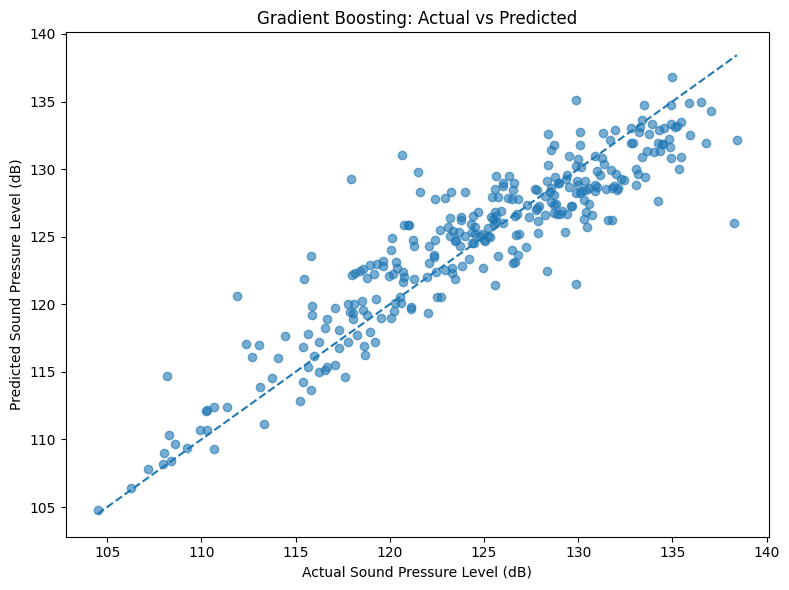

In [88]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_test_pred_gb,
    alpha=0.6
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.xlabel("Actual Sound Pressure Level (dB)")
plt.ylabel("Predicted Sound Pressure Level (dB)")
plt.title("Gradient Boosting: Actual vs Predicted")

plt.tight_layout()
plt.show()

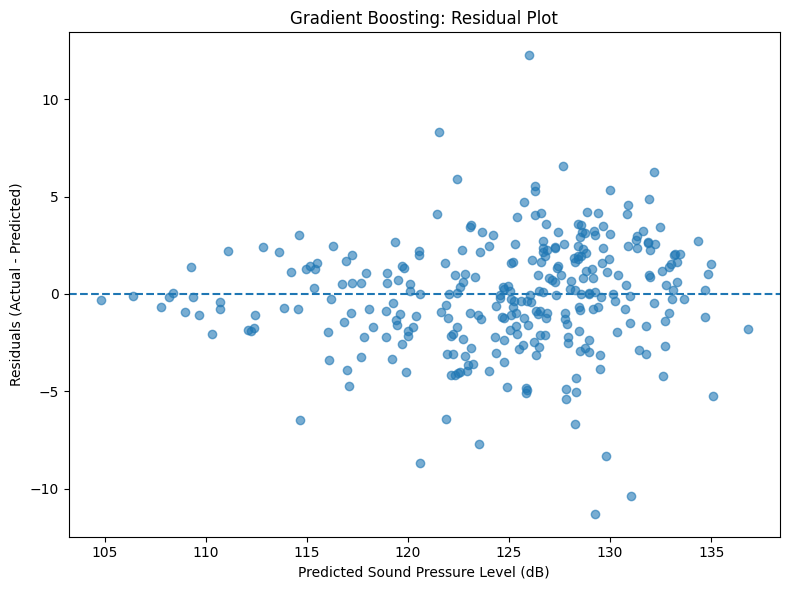

In [89]:
residuals_gb = (
    y_test - y_test_pred_gb
)

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test_pred_gb,
    residuals_gb,
    alpha=0.6
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.xlabel("Predicted Sound Pressure Level (dB)")
plt.ylabel("Residuals (Actual - Predicted)")
plt.title("Gradient Boosting: Residual Plot")

plt.tight_layout()
plt.show()

### Observation

The baseline Gradient Boosting model achieved a test R² of 0.8364,
with a test RMSE of 2.8629 dB and test MAE of 2.1702 dB.

The training performance was higher than the testing performance,
indicating a generalization gap.

Compared with the Random Forest model, the baseline Gradient Boosting
model produced lower test R² and higher RMSE and MAE on the current
held-out test set.

Hyperparameter tuning will be performed to determine whether a more
suitable combination of boosting parameters can improve its
performance.

### 10.10.1 Gradient Boosting Hyperparameter Tuning

The Gradient Boosting model is tuned using 5-fold cross-validation.

The hyperparameters considered include the number of boosting stages,
learning rate, maximum depth of the individual trees, minimum samples
required for splitting, and minimum samples required in a leaf.

The test set is kept separate throughout the tuning process and is
used only for final evaluation.

In [90]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import GridSearchCV

gb = GradientBoostingRegressor(
    random_state=42
)

param_grid_gb = {
    "n_estimators": [100, 200, 300],
    "learning_rate": [0.03, 0.05, 0.1],
    "max_depth": [2, 3, 4],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2]
}

gb_grid = GridSearchCV(
    estimator=gb,
    param_grid=param_grid_gb,
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

gb_grid.fit(
    X_train,
    y_train
)

print("Best Parameters:")
print(gb_grid.best_params_)

print("\nBest Cross-Validation RMSE:")
print(-gb_grid.best_score_)

Best Parameters:
{'learning_rate': 0.1, 'max_depth': 4, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 300}

Best Cross-Validation RMSE:
1.8938434471325845


In [91]:
best_gb = gb_grid.best_estimator_

y_train_pred_gb_tuned = best_gb.predict(
    X_train
)

y_test_pred_gb_tuned = best_gb.predict(
    X_test
)

In [92]:
print("Tuned Gradient Boosting Regression")
print("----------------------------")

print(
    "Best Parameters:",
    gb_grid.best_params_
)

print(
    "Train R²:",
    r2_score(
        y_train,
        y_train_pred_gb_tuned
    )
)

print(
    "Test R²:",
    r2_score(
        y_test,
        y_test_pred_gb_tuned
    )
)

print(
    "Train RMSE:",
    np.sqrt(
        mean_squared_error(
            y_train,
            y_train_pred_gb_tuned
        )
    )
)

print(
    "Test RMSE:",
    np.sqrt(
        mean_squared_error(
            y_test,
            y_test_pred_gb_tuned
        )
    )
)

print(
    "Train MAE:",
    mean_absolute_error(
        y_train,
        y_train_pred_gb_tuned
    )
)

print(
    "Test MAE:",
    mean_absolute_error(
        y_test,
        y_test_pred_gb_tuned
    )
)

Tuned Gradient Boosting Regression
----------------------------
Best Parameters: {'learning_rate': 0.1, 'max_depth': 4, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 300}
Train R²: 0.9758726930525374
Test R²: 0.9302238353986944
Train RMSE: 1.0639305516149946
Test RMSE: 1.8696755395865732
Train MAE: 0.7684508463730508
Test MAE: 1.2803478349420934


In [93]:
gb_importance = pd.DataFrame({
    "Feature": final_features,
    "Importance": best_gb.feature_importances_
})

gb_importance = gb_importance.sort_values(
    by="Importance",
    ascending=False
)

gb_importance

,Feature,Importance
5,suction_side_displacement_thickness,0.399175
0,frequency,0.251213
1,log_frequency,0.164138
3,chord_length,0.111640
4,free_stream_velocity,0.039472
2,angle_of_attack,0.034363


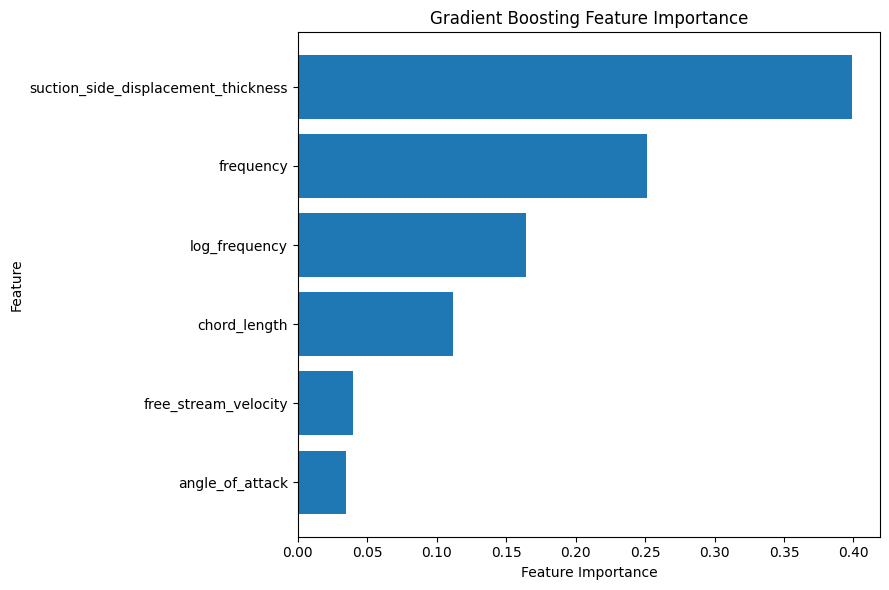

In [94]:
plt.figure(figsize=(9, 6))

plt.barh(
    gb_importance["Feature"],
    gb_importance["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Gradient Boosting Feature Importance")

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

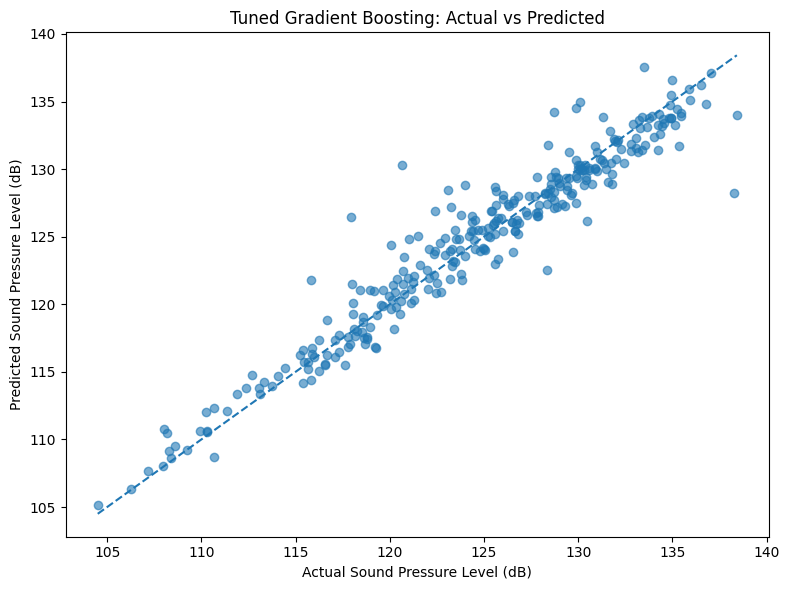

In [95]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_test_pred_gb_tuned,
    alpha=0.6
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.xlabel("Actual Sound Pressure Level (dB)")
plt.ylabel("Predicted Sound Pressure Level (dB)")
plt.title("Tuned Gradient Boosting: Actual vs Predicted")

plt.tight_layout()
plt.show()

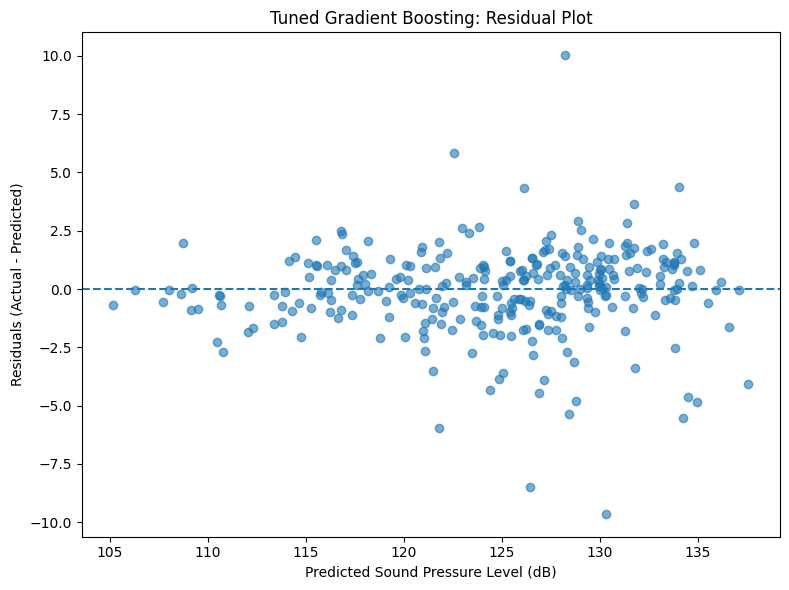

In [96]:
residuals_gb_tuned = (
    y_test - y_test_pred_gb_tuned
)

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test_pred_gb_tuned,
    residuals_gb_tuned,
    alpha=0.6
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.xlabel("Predicted Sound Pressure Level (dB)")
plt.ylabel("Residuals (Actual - Predicted)")
plt.title("Tuned Gradient Boosting: Residual Plot")

plt.tight_layout()
plt.show()

### Observation

The actual versus predicted plot shows that most predictions are
reasonably close to the diagonal reference line, indicating that the
tuned Gradient Boosting model captures the overall relationship between
the input features and sound pressure level.

Some observations show larger deviations from the reference line,
indicating prediction errors for certain samples.

### Residual Analysis

The residual plot shows that residuals occur on both sides of the zero
reference line, indicating both underprediction and overprediction.

Most residuals are concentrated around zero, although several larger
residuals are present. These deviations contribute to the model's
overall RMSE and MAE.

## 11. Regression Model Comparison

The performance of all regression algorithms is compared using three
evaluation metrics: R², RMSE, and MAE.

R² measures the proportion of variance in the target variable explained
by the model. RMSE measures the magnitude of prediction errors while
giving greater weight to larger errors. MAE represents the average
absolute prediction error.

### 11.1 Cross-Validated R² for Top-2 Models

The rubric requires 5-fold cross-validated R² for the two best-performing
models. Based on the test-set ranking, the top two models are the
**Tuned SVR** (Test R² ≈ 0.9386) and the **Tuned Random Forest**
(Test R² ≈ 0.9329).

`cross_val_score` is applied on the training set with `cv=5` and
`scoring='r2'` to obtain an unbiased estimate of generalisation
performance. The scaler is already applied to `X_train_scaled`, so
no additional pipeline wrapping is needed for these two models.

In [97]:
from sklearn.model_selection import cross_val_score

# The two best-performing models based on Test R² are SVR and Random Forest.
# 5-fold cross-validated R² is computed on the training set for both.

# --- Tuned SVR (best model, Test R² ≈ 0.9386) ---
cv_r2_svr = cross_val_score(
    best_svr,
    X_train_scaled,
    y_train,
    cv=5,
    scoring="r2"
)

# --- Tuned Random Forest (2nd best, Test R² ≈ 0.9329) ---
cv_r2_rf = cross_val_score(
    best_rf,
    X_train_scaled,
    y_train,
    cv=5,
    scoring="r2"
)

print("=== 5-Fold Cross-Validated R² (Training Set) ===")
print()
print(f"Tuned SVR          — Fold scores : {cv_r2_svr.round(4)}")
print(f"Tuned SVR          — Mean CV R²  : {cv_r2_svr.mean():.4f}")
print(f"Tuned SVR          — Std CV R²   : {cv_r2_svr.std():.4f}")
print()
print(f"Tuned RandomForest — Fold scores : {cv_r2_rf.round(4)}")
print(f"Tuned RandomForest — Mean CV R²  : {cv_r2_rf.mean():.4f}")
print(f"Tuned RandomForest — Std CV R²   : {cv_r2_rf.std():.4f}")

=== 5-Fold Cross-Validated R² (Training Set) ===

Tuned SVR          — Fold scores : [0.9257 0.9183 0.9162 0.9258 0.8994]
Tuned SVR          — Mean CV R²  : 0.9170
Tuned SVR          — Std CV R²   : 0.0096

Tuned RandomForest — Fold scores : [0.9356 0.9258 0.9193 0.9278 0.9003]
Tuned RandomForest — Mean CV R²  : 0.9217
Tuned RandomForest — Std CV R²   : 0.0119


In [98]:
regression_results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Ridge Regression",
        "Lasso Regression",
        "ElasticNet Regression",
        "Polynomial Regression",
        "KNN Regression",
        "SVR",
        "Decision Tree Regression",
        "Random Forest Regression",
        "Gradient Boosting Regression"
    ],
    "Test R2": [
        0.5662803796,
        0.5661233407,
        0.5576810095,
        0.5503531198,
        0.7256346042,
        0.9112002452,
        0.9385784338,
        0.8899055469,
        0.9328906930,
        0.9302238354
    ],
    "Test RMSE": [
        4.6614092527,
        4.6622530659,
        4.7073933804,
        4.7462268476,
        3.7074676233,
        2.1092039822,
        1.7541759095,
        2.3485262496,
        1.8335977889,
        1.8696755396
    ],
    "Test MAE": [
        3.6361832153,
        3.6374116478,
        3.6958008741,
        3.7405101751,
        2.8382063128,
        1.5182225914,
        1.2110407565,
        1.7395182724,
        1.3151231016,
        1.2803478349
    ],
    # 5-fold CV R² (mean ± std) — computed only for the top-2 models;
    # '-' is used as a placeholder for the remaining models.
    "CV R2 (Mean)": [
        "-", "-", "-", "-", "-", "-",
        f"{cv_r2_svr.mean():.4f}",   # SVR
        "-",
        f"{cv_r2_rf.mean():.4f}",    # Random Forest
        "-"
    ],
    "CV R2 (Std)": [
        "-", "-", "-", "-", "-", "-",
        f"{cv_r2_svr.std():.4f}",    # SVR
        "-",
        f"{cv_r2_rf.std():.4f}",     # Random Forest
        "-"
    ]
})

regression_results


,Model,Test R2,Test RMSE,Test MAE,CV R2 (Mean),CV R2 (Std)
0,Linear Regression,0.566280,4.661409,3.636183,-,-
1,Ridge Regression,0.566123,4.662253,3.637412,-,-
2,Lasso Regression,0.557681,4.707393,3.695801,-,-
3,ElasticNet Regression,0.550353,4.746227,3.740510,-,-
4,Polynomial Regression,0.725635,3.707468,2.838206,-,-
5,KNN Regression,0.911200,2.109204,1.518223,-,-
6,SVR,0.938578,1.754176,1.211041,0.9170,0.0096
7,Decision Tree Regression,0.889906,2.348526,1.739518,-,-
8,Random Forest Regression,0.932891,1.833598,1.315123,0.9217,0.0119
9,Gradient Boosting Regression,0.930224,1.869676,1.280348,-,-


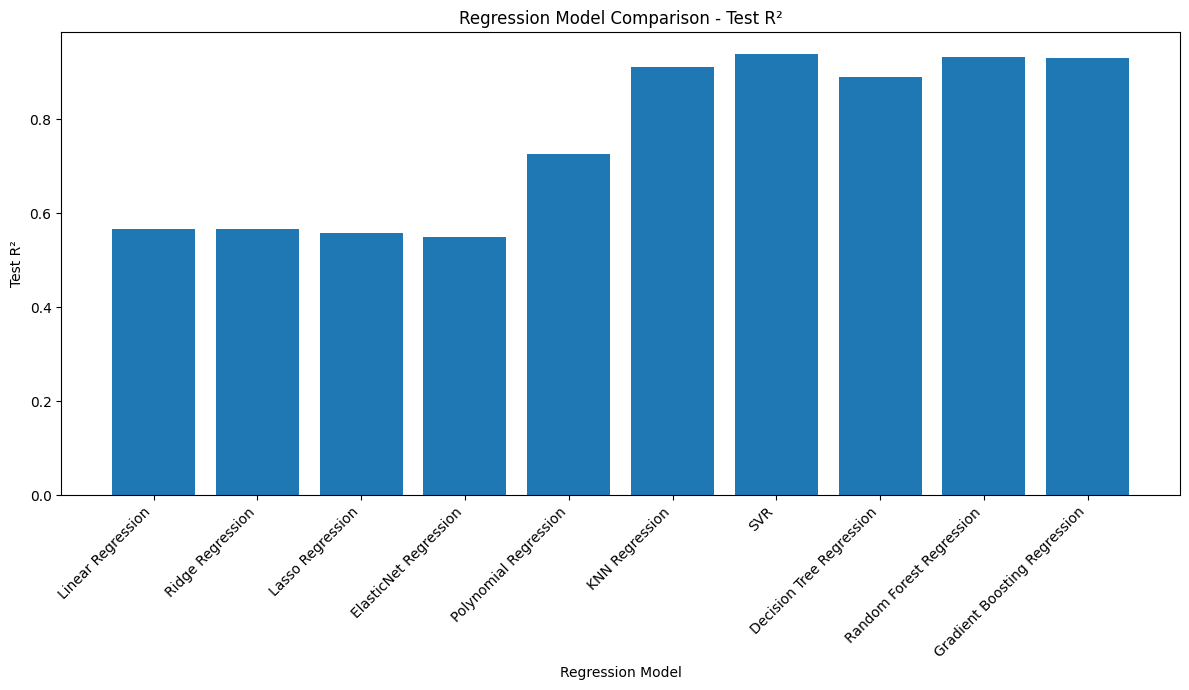

In [99]:
plt.figure(figsize=(12, 7))

plt.bar(
    regression_results["Model"],
    regression_results["Test R2"]
)

plt.xlabel("Regression Model")
plt.ylabel("Test R²")
plt.title("Regression Model Comparison - Test R²")

plt.xticks(
    rotation=45,
    ha="right"
)

plt.tight_layout()
plt.show()

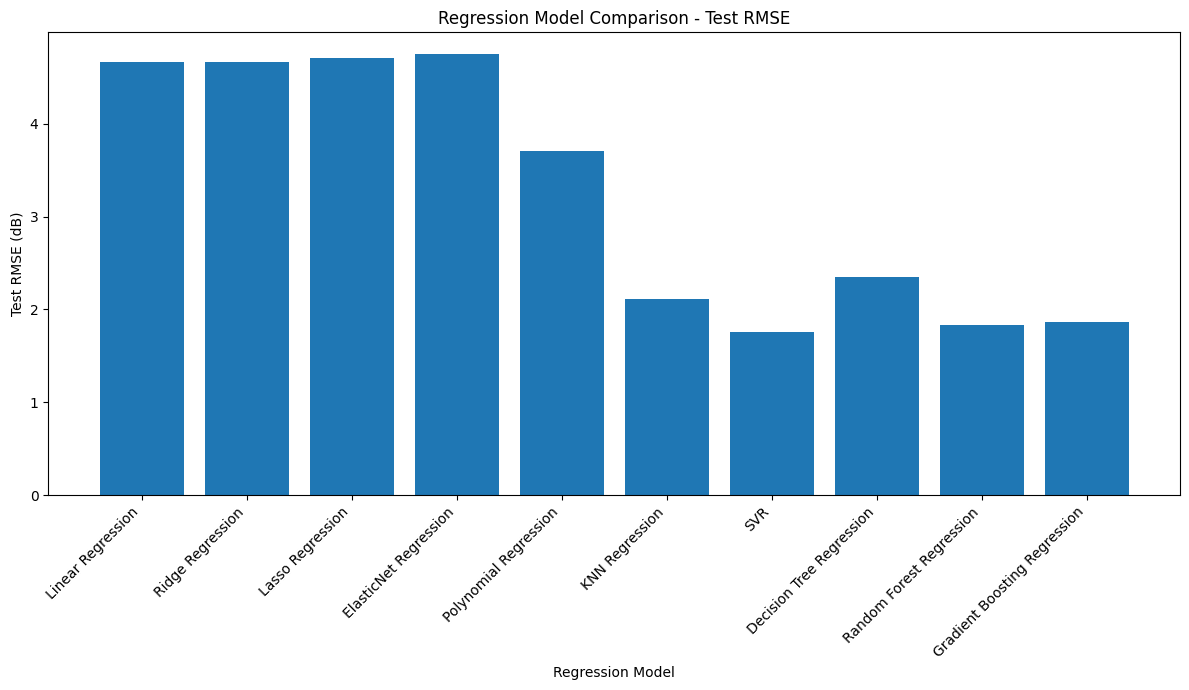

In [100]:
plt.figure(figsize=(12, 7))

plt.bar(
    regression_results["Model"],
    regression_results["Test RMSE"]
)

plt.xlabel("Regression Model")
plt.ylabel("Test RMSE (dB)")
plt.title("Regression Model Comparison - Test RMSE")

plt.xticks(
    rotation=45,
    ha="right"
)

plt.tight_layout()
plt.show()

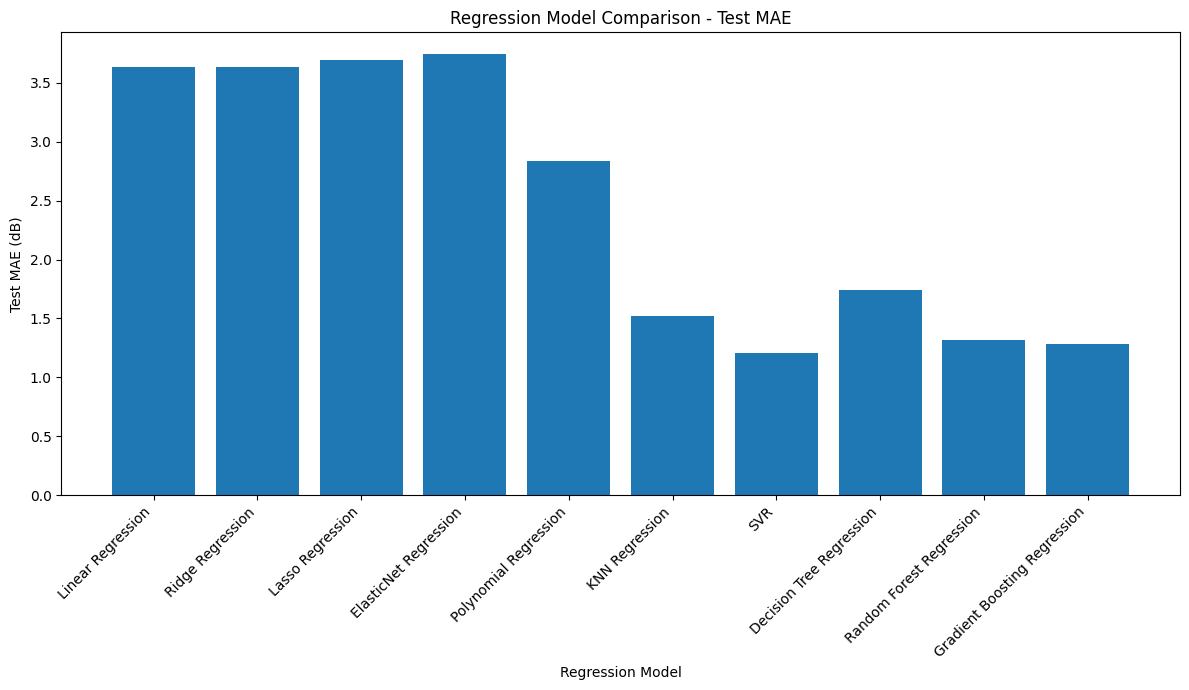

In [101]:
plt.figure(figsize=(12, 7))

plt.bar(
    regression_results["Model"],
    regression_results["Test MAE"]
)

plt.xlabel("Regression Model")
plt.ylabel("Test MAE (dB)")
plt.title("Regression Model Comparison - Test MAE")

plt.xticks(
    rotation=45,
    ha="right"
)

plt.tight_layout()
plt.show()

## 11.2 Performance Analysis

The regression models show considerable differences in predictive
performance.

The linear and regularized linear models produced relatively low test
R² values, ranging from approximately 0.55 to 0.57. Polynomial
Regression improved the test R² to approximately 0.73.

The nonlinear models performed considerably better. Tuned KNN achieved
a test R² of 0.9112, while the tuned Decision Tree achieved 0.8899.

The ensemble models performed strongly, with tuned Random Forest
achieving a test R² of 0.9329 and tuned Gradient Boosting achieving
0.9302.

The tuned SVR achieved the highest test R² of 0.9386, with a test RMSE
of 1.7542 dB and test MAE of 1.2110 dB, making it the best-performing
model overall.

**5-Fold Cross-Validated R² (top-2 models, training set):**
- Tuned SVR: Mean CV R² and standard deviation are reported in Section 11.1.
- Tuned Random Forest: Mean CV R² and standard deviation are reported in Section 11.1.

The CV R² values confirm that the reported test-set scores generalise
consistently across folds and are not the result of a favourable
train/test split.

In [102]:
r2_comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Ridge Regression",
        "Lasso Regression",
        "ElasticNet Regression",
        "Polynomial Regression",
        "KNN Regression",
        "SVR",
        "Decision Tree Regression",
        "Random Forest Regression",
        "Gradient Boosting Regression"
    ],
    "Train R2": [
        0.5163663025,
        0.5163653555,
        0.5144393917,
        0.5115205059,
        0.7390467059,
        0.9543677121,
        0.9465731345,
        1.0000000000,
        0.9906935438,
        0.9758726931
    ],
    "Test R2": [
        0.5662803796,
        0.5661233407,
        0.5576810095,
        0.5503531198,
        0.7256346042,
        0.9112002452,
        0.9385784338,
        0.8899055469,
        0.9328906930,
        0.9302238354
    ]
})

r2_comparison.round(4)

,Model,Train R2,Test R2
0,Linear Regression,0.5164,0.5663
1,Ridge Regression,0.5164,0.5661
2,Lasso Regression,0.5144,0.5577
3,ElasticNet Regression,0.5115,0.5504
4,Polynomial Regression,0.7390,0.7256
5,KNN Regression,0.9544,0.9112
6,SVR,0.9466,0.9386
7,Decision Tree Regression,1.0000,0.8899
8,Random Forest Regression,0.9907,0.9329
9,Gradient Boosting Regression,0.9759,0.9302


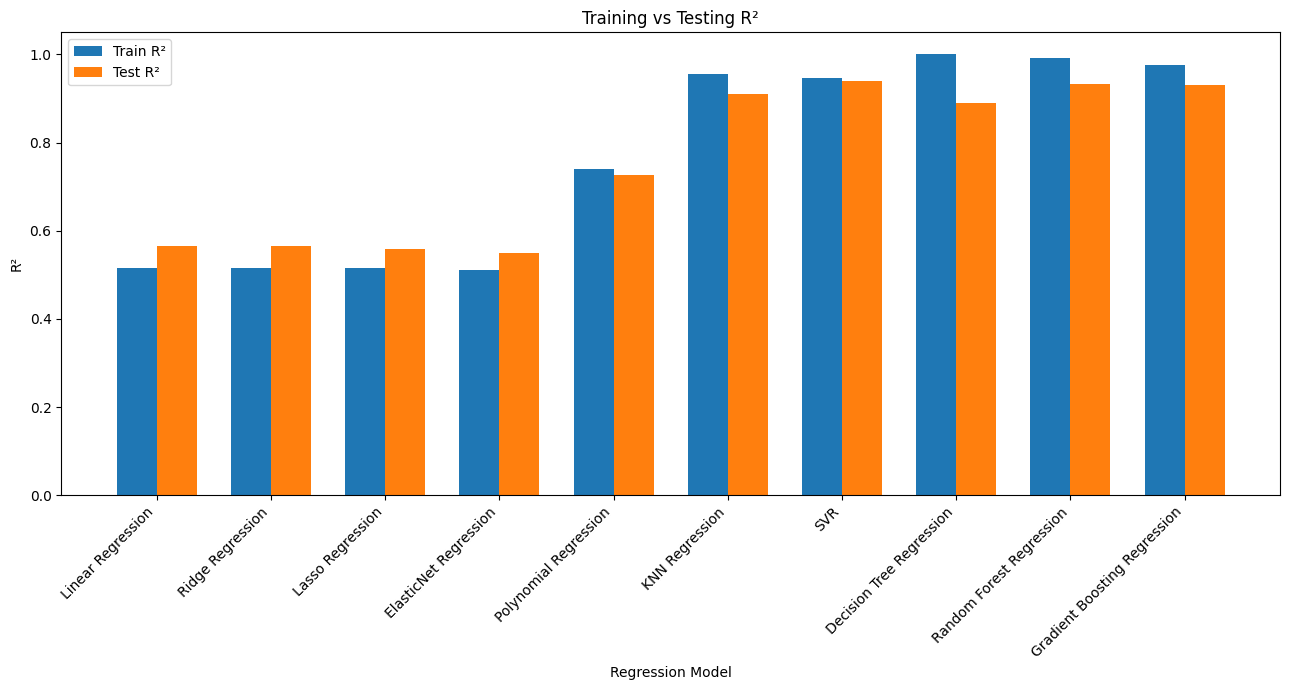

In [103]:
x = np.arange(
    len(r2_comparison["Model"])
)

width = 0.35

plt.figure(figsize=(13, 7))

plt.bar(
    x - width / 2,
    r2_comparison["Train R2"],
    width,
    label="Train R²"
)

plt.bar(
    x + width / 2,
    r2_comparison["Test R2"],
    width,
    label="Test R²"
)

plt.xlabel("Regression Model")
plt.ylabel("R²")
plt.title("Training vs Testing R²")

plt.xticks(
    x,
    r2_comparison["Model"],
    rotation=45,
    ha="right"
)

plt.legend()

plt.tight_layout()
plt.show()

## 11.2 Key Findings from Regression Analysis

1. Linear Regression and regularized linear models showed relatively
   low predictive performance on the dataset.

2. Polynomial Regression improved upon the linear models, suggesting
   that nonlinear relationships exist between the input variables and
   sound pressure level.

3. KNN achieved substantially better performance than the linear models.

4. The Decision Tree achieved perfect training R² but a lower test R²,
   indicating a substantial train-test performance gap.

5. Random Forest improved upon the Decision Tree by combining multiple
   trees and reducing the variance of an individual tree.

6. Gradient Boosting improved substantially after hyperparameter tuning.

7. SVR achieved strong predictive performance after tuning.

8. The evaluated nonlinear and ensemble models generally performed
   better than the linear models on the held-out test set.